# TP Integrador · Análisis de Datos (CEIA · FIUBA 2026)
## Predicción de reingreso hospitalario en < 30 días · Pacientes diabéticos, 130 hospitales de EE.UU. (1999-2008)

**Objetivo del trabajo:** explorar el dataset, plantear un problema de ML supervisado y dejar los datos
**listos para entrenar un modelo** (limpieza, faltantes, outliers, split, escalado, codificación,
balanceo, selección de features y PCA). El entrenamiento es *opcional* (sección 15) y no es necesario para la consigna.

**Cómo está organizado**

| # | Sección | Consigna del enunciado |
|---|---------|------------------------|
| 1-2 | Carga y descripción | Exploración y comprensión |
| 3-4 | EDA univariado y bivariado | Visualización e interpretación |
| 5 | Calidad de datos: faltantes (MCAR/MAR/MNAR/estructural), nulos encubiertos | Errores y faltantes |
| 6 | Planteo del problema supervisado | Definir target |
| 7-8 | Limpieza, feature engineering y split por paciente | Preprocesamiento |
| 9 | Outliers | Detectar **y manejar** |
| 10-11 | Pipeline (codificación, discretización, escalado) y balance de clases | Feature engineering |
| 12-13 | Selección de features y PCA | Reducción de dimensionalidad |
| 14 | **Pruebas de aptitud**: ¿el dataset sirve para un modelo? | Verificación |
| 15 | **Opcional**: entrenamiento de modelos | Extra |

**Principio rector:** *ninguna decisión que aprenda de los datos (cuantiles, medias, categorías, filtros)
se toma con el test*. Todo estimador se ajusta (`fit`) solo con train y luego se aplica (`transform`) a test.
Eso evita **data leakage**, que es la principal fuente de métricas optimistas en la práctica.

## 0. Configuración

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt   # solo para abrir una figura nueva con tamaño fijo
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

# ---- Parámetros globales: todo lo "ajustable" vive acá ----
RANDOM_STATE = 42            # reproducibilidad
ENTRENAR_MODELO = True       # False -> se omite la sección 15 (el TP no requiere entrenar)
GUARDAR_SALIDA = False       # True -> exporta las matrices finales a ./salida
TEST_SIZE_FOLDS = 5          # StratifiedGroupKFold(5) -> 80 % train / 20 % test
UMBRAL_CORRELACION = 0.90    # |rho| a partir del cual dos features se consideran redundantes
FRECUENCIA_MINIMA = 0.01     # categorías con < 1 % de frecuencia se agrupan en "infrecuente"
PERCENTILES_WINSOR = (0.01, 0.99)

# Ruta relativa: funciona tanto parado en tp_final/ como en la raíz del repo
RUTA_DATOS = next(p for p in (Path('content'), Path('tp_final/content')) if p.exists())

# Estilo único de seaborn para todo el notebook
COLOR_NEG, COLOR_POS = '#4C72B0', '#C44E52'
PALETA_TARGET = {0: COLOR_NEG, 1: COLOR_POS}


def fijar_tamano(ancho: float, alto: float) -> None:
    """Abre una figura nueva con el estilo del notebook. Todo el dibujo posterior es 100 % seaborn;
    matplotlib se usa únicamente para crear el lienzo (seaborn dibuja sobre el eje activo)."""
    sns.set_theme(style='whitegrid', context='notebook', palette='deep', rc={'axes.titleweight': 'bold'})
    plt.figure(figsize=(ancho, alto))


sns.set_theme(style='whitegrid', context='notebook', palette='deep')

## 1. Carga de datos

El dataset (UCI, *Diabetes 130-US hospitals 1999-2008*) tiene **un registro por internación** (`encounter`).
Un mismo paciente (`patient_nbr`) puede tener varias internaciones: esto condiciona el split (sección 8).

Dos decisiones de lectura:
* `'?'` es el marcador de faltante del dataset → se lee como `NaN`.
* `keep_default_na=False`: pandas interpretaría `'None'` como `NaN`, pero en `max_glu_serum` y `A1Cresult`
  `'None'` significa **"el examen no se realizó"** (información, no ausencia de dato). Lo conservamos como texto
  y lo recodificamos explícitamente más adelante.

In [2]:
df_raw = pd.read_csv(RUTA_DATOS / 'diabetic_data.csv', na_values=['?'],
                     keep_default_na=False, low_memory=False)


def cargar_mapeo_ids(ruta: Path) -> dict[str, dict[int, str]]:
    """Parsea IDS_mapping.csv: tres tablas (id → descripción) separadas por una fila vacía."""
    mapeos: dict[str, dict[int, str]] = {}
    actual = None
    filas = pd.read_csv(ruta, header=None, dtype=str, keep_default_na=False)
    for id_, descripcion in filas.itertuples(index=False):
        id_, descripcion = id_.strip(), descripcion.strip()
        if id_ == '':                       # fila separadora
            actual = None
        elif descripcion == 'description':  # encabezado de una nueva tabla
            actual = id_
            mapeos[actual] = {}
        else:
            mapeos[actual][int(id_)] = descripcion
    return mapeos


mapeos = cargar_mapeo_ids(RUTA_DATOS / 'IDS_mapping.csv')
print({col: len(m) for col, m in mapeos.items()})
print(f'Dataset crudo: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas')
df_raw.head(3)

{'admission_type_id': 8, 'discharge_disposition_id': 30, 'admission_source_id': 25}
Dataset crudo: 101,766 filas × 50 columnas


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


## 2. Descripción general

Antes de graficar conviene un **perfil estructural**: tipo, cardinalidad y % de nulos de cada columna.
La cardinalidad decide cómo se trata cada variable (una columna con 700 categorías no se codifica igual
que una binaria) y el % de nulos decide si imputar, crear categoría propia o descartar.

In [3]:
perfil = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'n_unicos': df_raw.nunique(),
    '%_nulos': (df_raw.isna().mean() * 100).round(2),
    'moda': df_raw.mode().iloc[0],
})
print(f'Filas duplicadas (completas): {df_raw.duplicated().sum()} | '
      f'encounter_id duplicados: {df_raw.encounter_id.duplicated().sum()}')
print(f'Pacientes distintos: {df_raw.patient_nbr.nunique():,}')
perfil

Filas duplicadas (completas): 0 | encounter_id duplicados: 0
Pacientes distintos: 71,518


,dtype,n_unicos,%_nulos,moda
encounter_id,int64,101766,0.00,12522
patient_nbr,int64,71518,0.00,88785891.0
race,str,5,2.23,Caucasian
gender,str,3,0.00,Female
age,str,10,0.00,[70-80)
weight,str,9,96.86,[75-100)
admission_type_id,int64,8,0.00,1.0
discharge_disposition_id,int64,26,0.00,1.0
admission_source_id,int64,17,0.00,7.0
time_in_hospital,int64,14,0.00,3.0


**Lectura del perfil**
* 50 columnas: 2 identificadores, 8 conteos numéricos, ~12 categóricas clínicas/demográficas, 23 medicamentos,
  y la variable `readmitted`.
* `examide` y `citoglipton` tienen un único valor → **constantes**, no aportan información.
* `weight` (~97 % nulo), `max_glu_serum` y `A1Cresult` tienen faltantes masivos → se analizan en la sección 5.
* No hay encuentros duplicados.

### Tipificación de variables
El tipo estadístico determina qué gráfico, qué test y qué codificación son válidos.
Un error típico acá: tratar `admission_type_id` (un **código**) como número y calcular su media.

In [4]:
IDENTIFICADORES = ['encounter_id', 'patient_nbr']
CONTEOS = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
           'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
CODIGOS_NOMINALES = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']   # numéricos solo en apariencia
NOMINALES_DEMOGRAFICAS = ['race', 'gender']
ORDINALES_NATURALES = ['age', 'weight']          # intervalos con orden natural
RESULTADOS_LAB = ['max_glu_serum', 'A1Cresult']  # valores: no medido / normal / alto / muy alto
MEDICAMENTOS = df_raw.loc[:, 'metformin':'metformin-pioglitazone'].columns.tolist()
DIAGNOSTICOS = ['diag_1', 'diag_2', 'diag_3']
TARGET_ORIGINAL = 'readmitted'

tipos = pd.Series({
    **{c: 'identificador' for c in IDENTIFICADORES},
    **{c: 'numérica (conteo)' for c in CONTEOS},
    **{c: 'nominal (código)' for c in CODIGOS_NOMINALES},
    **{c: 'nominal' for c in NOMINALES_DEMOGRAFICAS + DIAGNOSTICOS + ['payer_code', 'medical_specialty', 'change', 'diabetesMed']},
    **{c: 'ordinal' for c in ORDINALES_NATURALES + RESULTADOS_LAB + [TARGET_ORIGINAL]},
    **{c: 'nominal (estado de medicación)' for c in MEDICAMENTOS},
})
print(tipos.value_counts().to_string())
assert set(tipos.index) == set(df_raw.columns), 'hay columnas sin tipificar'

nominal (estado de medicación)    23
nominal                            9
numérica (conteo)                  8
ordinal                            5
nominal (código)                   3
identificador                      2


## 3. EDA univariado

### 3.1 Variable objetivo original
`readmitted` tiene 3 clases: `NO` (sin reingreso), `>30` (reingreso tardío) y `<30` (reingreso temprano).
Para una variable **categórica ordinal** el gráfico adecuado es un *barplot de frecuencias* con el orden respetado
(un gráfico de torta distorsiona la comparación de magnitudes).

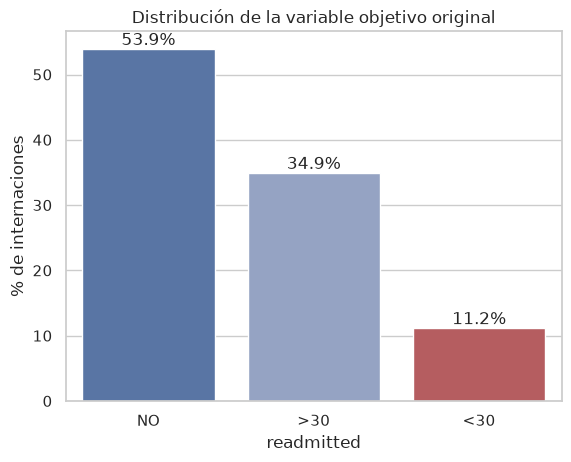

In [5]:
ORDEN_READMITTED = ['NO', '>30', '<30']
frec = (df_raw[TARGET_ORIGINAL].value_counts(normalize=True).reindex(ORDEN_READMITTED) * 100).reset_index()
frec.columns = ['readmitted', 'porcentaje']

ax = sns.barplot(data=frec, x='readmitted', y='porcentaje', hue='readmitted', legend=False,
                 palette=[COLOR_NEG, '#8DA0CB', COLOR_POS])
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.1f%%')
ax.set_title('Distribución de la variable objetivo original')
ax.set_ylabel('% de internaciones');

> **Interpretación:** solo ~11 % de las internaciones terminan en reingreso temprano (`<30`). Es el evento de
> interés clínico (los sistemas de salud penalizan reingresos evitables) y es la **clase minoritaria**: aparecerá un
> problema de desbalance que se trata en la sección 11.

### 3.2 Variables numéricas (conteos)
Para variables numéricas continuas/discretas el gráfico estándar es el **histograma**. Acompañamos con
**asimetría** (skewness) y **curtosis**, porque guían las transformaciones posteriores:
`|skew| > 1` suele indicar una cola derecha lo bastante pesada como para justificar `log1p`.

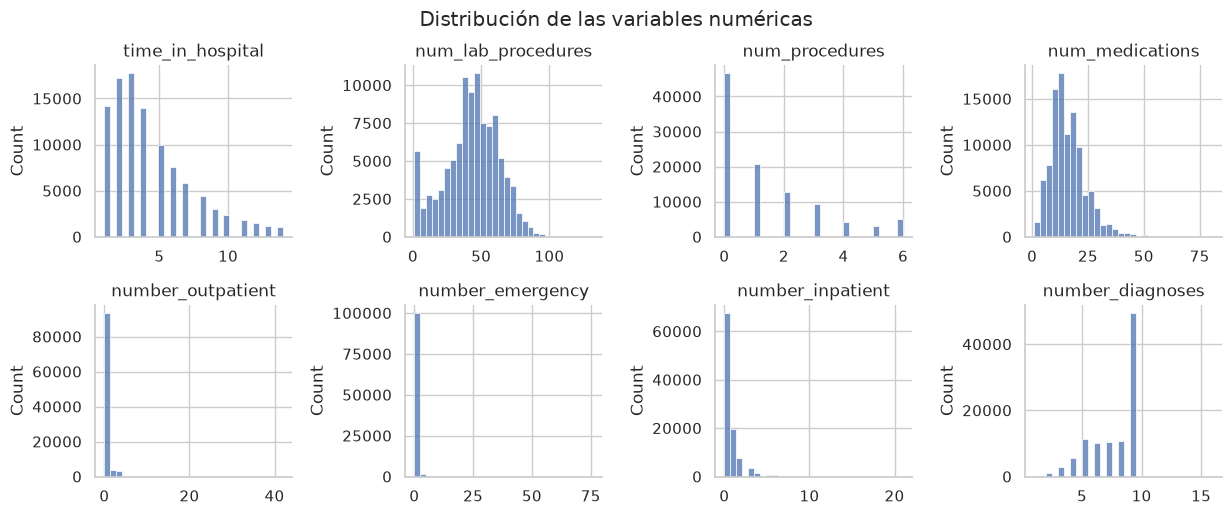

In [6]:
def grilla_histogramas(data_larga: pd.DataFrame, **kwargs_facet) -> sns.FacetGrid:
    """Un histograma por variable con ejes propios (cada variable vive en una escala distinta)."""
    grilla = sns.FacetGrid(data_larga, sharex=False, sharey=False, **kwargs_facet)
    grilla.map_dataframe(sns.histplot, x='valor', bins=30, color=COLOR_NEG)
    grilla.set_titles('{col_name}')
    grilla.set_xlabels('')
    return grilla


largo = df_raw[CONTEOS].melt(var_name='variable', value_name='valor')
g = grilla_histogramas(largo, col='variable', col_wrap=4, height=2.6, aspect=1.2)
g.figure.suptitle('Distribución de las variables numéricas', y=1.03);

In [7]:
resumen_num = df_raw[CONTEOS].agg(['mean', 'median', 'std', 'min', 'max', 'skew', 'kurt']).T.round(2)
resumen_num['%_ceros'] = (df_raw[CONTEOS].eq(0).mean() * 100).round(1)
resumen_num

,mean,median,std,min,max,skew,kurt,%_ceros
time_in_hospital,4.40,4.0,2.99,1.0,14.0,1.13,0.85,0.0
num_lab_procedures,43.10,44.0,19.67,1.0,132.0,-0.24,-0.25,0.0
num_procedures,1.34,1.0,1.71,0.0,6.0,1.32,0.86,45.8
num_medications,16.02,15.0,8.13,1.0,81.0,1.33,3.47,0.0
number_outpatient,0.37,0.0,1.27,0.0,42.0,8.83,147.91,83.6
number_emergency,0.20,0.0,0.93,0.0,76.0,22.86,1191.69,88.8
number_inpatient,0.64,0.0,1.26,0.0,21.0,3.61,20.72,66.5
number_diagnoses,7.42,8.0,1.93,1.0,16.0,-0.88,-0.08,0.0


> **Interpretación**
> * `time_in_hospital`, `num_medications`, `num_procedures`: asimetría positiva moderada (típico de tiempos y conteos).
> * `number_outpatient`, `number_emergency`, `number_inpatient`: **cero-inflados** (la mayoría de los pacientes no
>   tiene visitas previas) y con colas extremas (`number_emergency` llega a 76, asimetría ≈ 22).
> * `num_lab_procedures` es casi simétrica y `number_diagnoses` se acumula en 9 (límite de carga del sistema).

### 3.3 Variables categóricas
Se grafican las proporciones **ordenadas por frecuencia** (o por orden natural si es ordinal) en barras
horizontales, que permiten leer etiquetas largas. Las variables de alta cardinalidad se limitan al *top-N*.

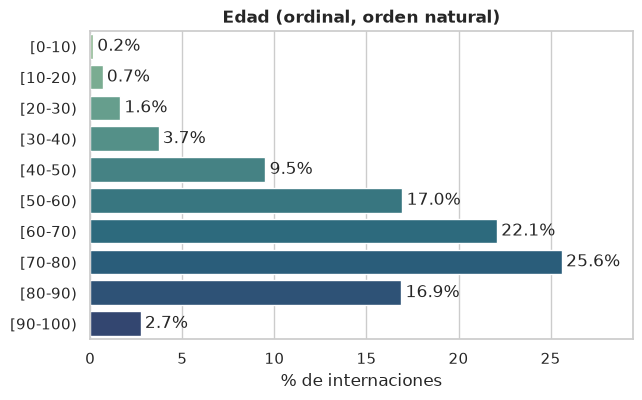

In [8]:
def grafico_frecuencias(data: pd.DataFrame, columna: str, orden: list | None = None,
                        top: int = 12, titulo: str | None = None):
    """Barras horizontales de proporción (%) de una variable categórica."""
    conteo = (data[columna].astype(str).value_counts(normalize=True) * 100)
    conteo = conteo.reindex(orden).dropna() if orden else conteo.head(top)
    ax = sns.barplot(x=conteo.values, y=conteo.index, hue=conteo.index, legend=False,
                     palette='crest', orient='h')
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.1f%%', padding=3)
    ax.set_title(titulo or f'{columna} ({data[columna].nunique()} categorías)')
    ax.set_xlabel('% de internaciones'); ax.set_ylabel('')
    ax.set_xlim(0, conteo.max() * 1.15)
    return ax


ORDEN_EDAD = [f'[{i}-{i + 10})' for i in range(0, 100, 10)]
fijar_tamano(7, 4)
grafico_frecuencias(df_raw, 'age', ORDEN_EDAD, titulo='Edad (ordinal, orden natural)');

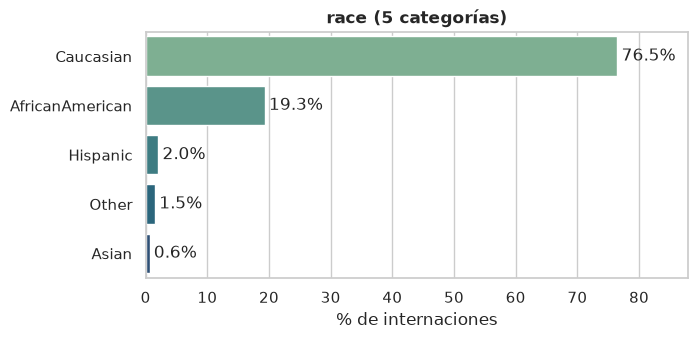

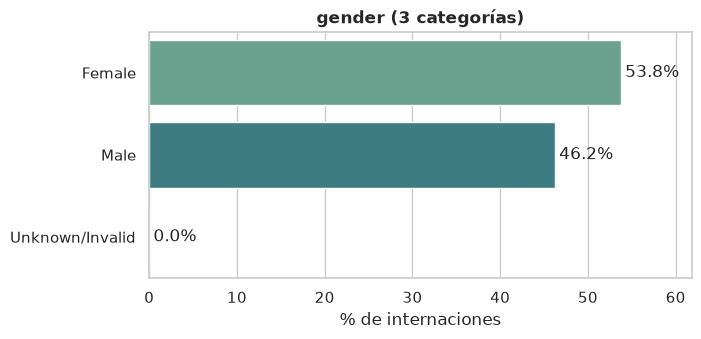

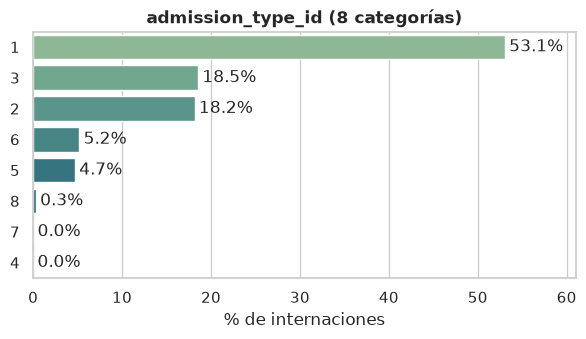

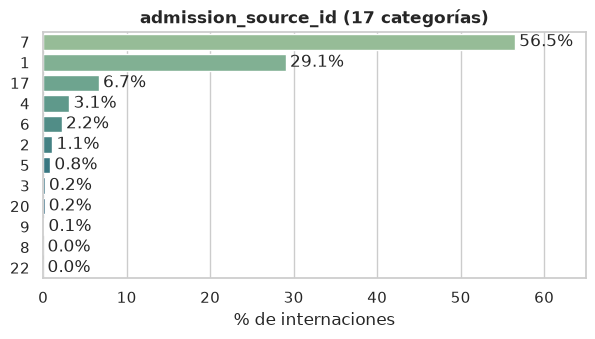

In [9]:
for col in ['race', 'gender', 'admission_type_id', 'admission_source_id']:
    fijar_tamano(7, 3.2)
    grafico_frecuencias(df_raw, col)

> **Interpretación:** población mayoritariamente caucásica y de edad avanzada (> 60 años), con ingreso principal
> por urgencias. Hay categorías dominantes y una cola larga: justifica agrupar categorías raras (sección 10).
> Además `gender` contiene 3 registros `Unknown/Invalid` (error de captura) que se eliminarán.

### 3.4 Medicamentos
23 columnas con 4 estados (`No`, `Steady`, `Up`, `Down`). Resumirlas en **una sola figura** (% de internaciones con
cada fármaco activo) es más legible que 23 gráficos.

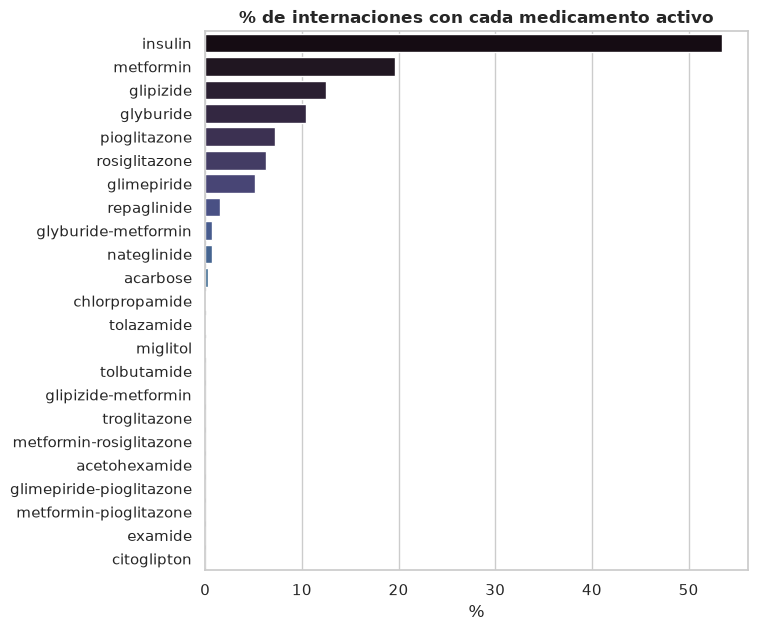

In [10]:
uso_med = ((df_raw[MEDICAMENTOS] != 'No').mean() * 100).sort_values(ascending=False).reset_index()
uso_med.columns = ['medicamento', 'porcentaje']
fijar_tamano(7, 7)
ax = sns.barplot(data=uso_med, x='porcentaje', y='medicamento', hue='medicamento', legend=False, palette='mako')
ax.set_title('% de internaciones con cada medicamento activo'); ax.set_xlabel('%'); ax.set_ylabel('');

> **Interpretación:** `insulin` (53 %) y `metformin` (20 %) dominan; `glipizide`, `glyburide`, `pioglitazone`,
> `rosiglitazone` y `glimepiride` están entre 5 % y 12 %. El resto está activo en ≤ 1.5 % de las internaciones (casi constantes).
> Esto anticipa un filtro de **varianza casi nula** en la selección de features.

## 4. EDA bivariado: relación de cada variable con el reingreso

Definimos ya el indicador binario `reingreso_30d` (1 = `<30`) para **explorar** asociaciones. Para comparar una
variable categórica contra un target binario, el gráfico adecuado es la **tasa de positivos por categoría**
(con su tamaño muestral); la línea punteada es la tasa global (referencia de independencia).

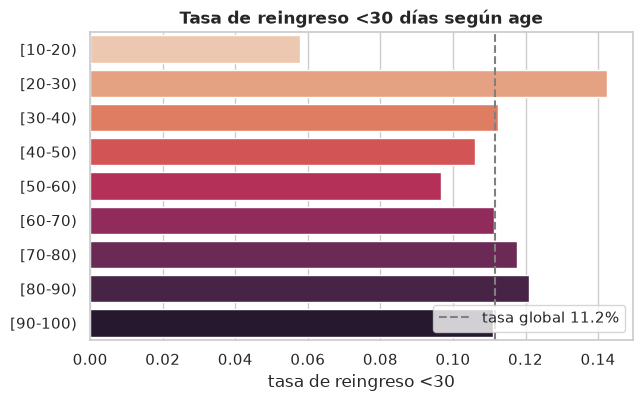

In [11]:
df_eda = df_raw.assign(reingreso_30d=(df_raw[TARGET_ORIGINAL] == '<30').astype(int))


def grafico_tasa(data: pd.DataFrame, columna: str, orden: list | None = None,
                 min_n: int = 300, titulo: str | None = None):
    """Tasa de reingreso por categoría. Se omiten categorías con menos de `min_n` casos
    porque su tasa es muy ruidosa (error estándar ~ sqrt(p(1-p)/n))."""
    tasa_global = data['reingreso_30d'].mean()
    tabla = data.groupby(columna)['reingreso_30d'].agg(tasa='mean', n='size').reset_index()
    tabla = tabla[tabla['n'] >= min_n]
    tabla[columna] = tabla[columna].astype(str)
    if orden:
        tabla = tabla.set_index(columna).reindex([o for o in orden if o in set(tabla[columna])]).reset_index()
    else:
        tabla = tabla.sort_values('tasa', ascending=False)
    ax = sns.barplot(data=tabla, x='tasa', y=columna, hue=columna, legend=False, palette='rocket_r', orient='h')
    ax.axvline(tasa_global, ls='--', color='gray', label=f'tasa global {tasa_global:.1%}')
    ax.set_title(titulo or f'Tasa de reingreso <30 días según {columna}')
    ax.set_xlabel('tasa de reingreso <30'); ax.set_ylabel('')
    ax.legend(loc='lower right')
    return ax


fijar_tamano(7, 4)
grafico_tasa(df_eda, 'age', ORDEN_EDAD);

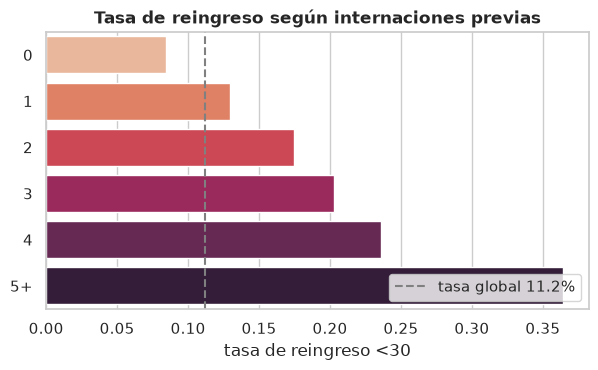

In [12]:
df_eda['number_inpatient_cap'] = df_eda['number_inpatient'].clip(upper=5).astype(int).astype(str).replace('5', '5+')
fijar_tamano(7, 3.6)
grafico_tasa(df_eda, 'number_inpatient_cap', ['0', '1', '2', '3', '4', '5+'],
             titulo='Tasa de reingreso según internaciones previas');

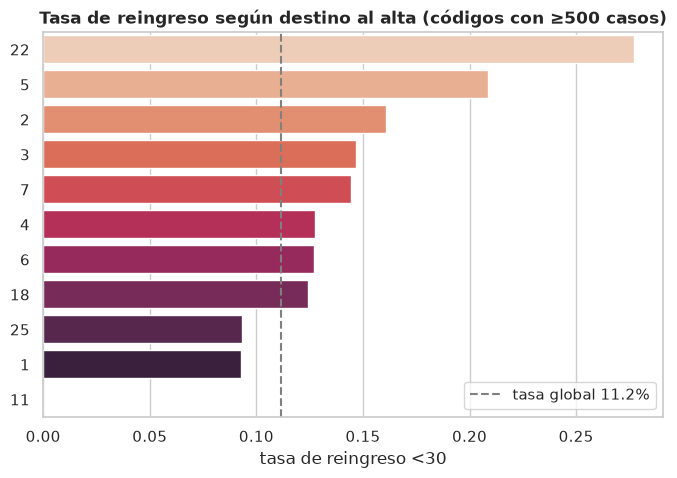

In [13]:
fijar_tamano(8, 5)
grafico_tasa(df_eda, 'discharge_disposition_id', min_n=500,
             titulo='Tasa de reingreso según destino al alta (códigos con ≥500 casos)');

> **Interpretación**
> * **Internaciones previas** es el predictor más claro: la tasa de reingreso crece de forma monótona con el historial.
>   Tiene sentido clínico: es un proxy de severidad/cronicidad.
> * El **destino al alta** separa fuerte: alta a centros de rehabilitación/enfermería tiene más reingreso que alta a domicilio.
> * La **edad** tiene un efecto no lineal: los menores de 20 años tienen la tasa más baja (< 6 %), hay un pico en 20-30 años
>   (≈ 14 %, grupo pequeño y ruidoso) y luego una meseta cercana al promedio (≈ 10-12 %).
> * `discharge_disposition_id = 11` (fallecidos) tiene tasa 0: confirma que son negativos garantizados (sección 5.5).

### 4.1 Relación numérica-numérica: correlación de **Spearman**
Spearman (basada en rangos) es preferible a Pearson acá porque las variables son conteos asimétricos con outliers:
Pearson mide solo asociación **lineal** y es sensible a valores extremos.

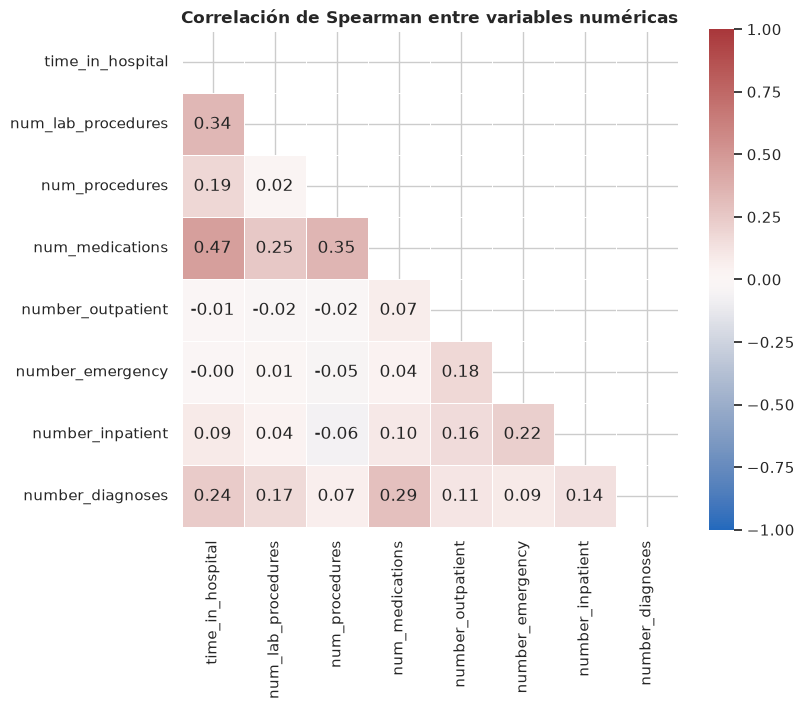

In [14]:
corr_spearman = df_raw[CONTEOS].corr(method='spearman')
fijar_tamano(8, 6.5)
ax = sns.heatmap(corr_spearman, mask=np.triu(np.ones_like(corr_spearman, dtype=bool)), annot=True, fmt='.2f',
                 cmap='vlag', center=0, vmin=-1, vmax=1, square=True, linewidths=.5)
ax.set_title('Correlación de Spearman entre variables numéricas');

> **Interpretación:** las asociaciones más altas son `num_medications` ↔ `time_in_hospital` (ρ ≈ 0.47),
> `num_medications` ↔ `num_procedures` (≈ 0.35) y `time_in_hospital` ↔ `num_lab_procedures` (≈ 0.34): internaciones
> más largas y complejas reciben más fármacos, procedimientos y estudios. Ningún par supera |ρ| = 0.5, por lo que
> **no hay redundancia numérica severa**.

### 4.2 Relación categórica-categórica: **V de Cramér**
Mide asociación entre dos nominales en [0, 1]. Usamos la versión con **corrección de sesgo de Bergsma**, porque
el V clásico se infla artificialmente cuando hay muchas categorías.

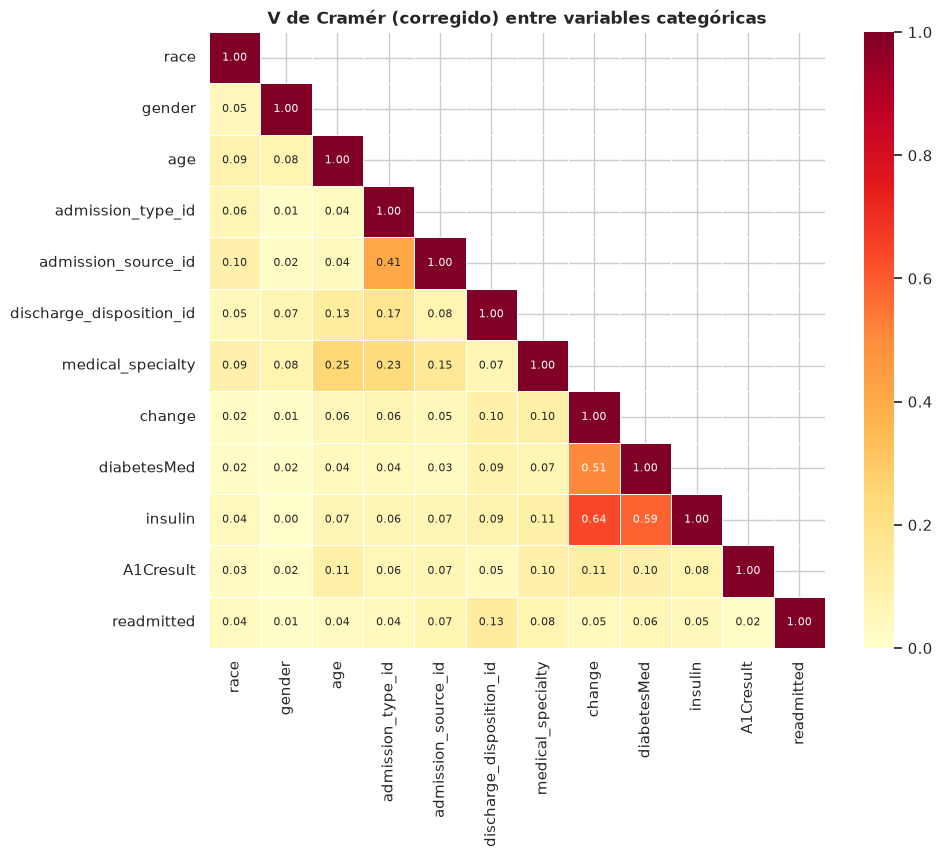

In [15]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """V de Cramér con corrección de Bergsma (2013)."""
    tabla = pd.crosstab(x, y)
    tabla = tabla.loc[tabla.sum(axis=1) > 0, tabla.sum(axis=0) > 0]
    if min(tabla.shape) < 2:
        return np.nan
    chi2 = stats.chi2_contingency(tabla).statistic
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    phi2 = max(0.0, chi2 / n - (r - 1) * (k - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    denominador = min(r_corr - 1, k_corr - 1)
    return float(np.sqrt(phi2 / denominador)) if denominador > 0 else np.nan


def matriz_cramer(data: pd.DataFrame, columnas: list[str]) -> pd.DataFrame:
    m = pd.DataFrame(np.eye(len(columnas)), index=columnas, columns=columnas)
    for i, a in enumerate(columnas):
        for b in columnas[i + 1:]:
            m.loc[a, b] = m.loc[b, a] = cramers_v(data[a].astype(str), data[b].astype(str))
    return m


cols_cramer = ['race', 'gender', 'age', 'admission_type_id', 'admission_source_id', 'discharge_disposition_id',
               'medical_specialty', 'change', 'diabetesMed', 'insulin', 'A1Cresult', 'readmitted']
cramer = matriz_cramer(df_eda.fillna('Faltante'), cols_cramer)
fijar_tamano(10, 8)
ax = sns.heatmap(cramer, mask=np.triu(np.ones_like(cramer, dtype=bool), k=1), annot=True, fmt='.2f',
                 cmap='YlOrRd', vmin=0, vmax=1, square=True, linewidths=.5, annot_kws={'size': 8})
ax.set_title('V de Cramér (corregido) entre variables categóricas');

> **Interpretación:** `change` ↔ `diabetesMed` (V ≈ 0.51) y `admission_type_id` ↔ `admission_source_id` (V ≈ 0.41) están
> fuertemente asociadas (redundantes por diseño clínico/administrativo). Contra `readmitted`, la mayor asociación es
> `discharge_disposition_id` (V ≈ 0.13) y el resto queda por debajo de 0.08: **la señal está distribuida y es débil**,
> esperable en un problema de reingresos.

## 5. Calidad de datos: faltantes, nulos encubiertos y consistencia

### 5.1 Taxonomía de faltantes (Rubin, 1976)
| Tipo | Definición | Consecuencia |
|------|-----------|--------------|
| **MCAR** | La probabilidad de falta no depende de nada | Eliminar/imputar no sesga |
| **MAR** | Depende de variables **observadas** | Imputar condicionando a esas variables |
| **MNAR** | Depende del propio valor no observado | No imputable sin supuestos; modelar la ausencia |
| **Estructural** | Falta *por diseño* (no aplica / no se realizó) | La ausencia **es** información: categoría propia |

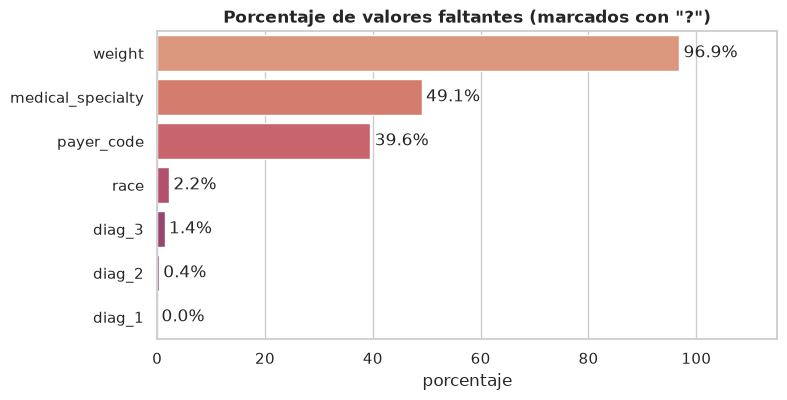

In [16]:
nulos = (df_raw.isna().mean() * 100).loc[lambda s: s > 0].sort_values(ascending=False).reset_index()
nulos.columns = ['variable', 'porcentaje']

fijar_tamano(8, 4)
ax = sns.barplot(data=nulos, x='porcentaje', y='variable', hue='variable', legend=False, palette='flare', orient='h')
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.1f%%', padding=3)
ax.set_title('Porcentaje de valores faltantes (marcados con "?")'); ax.set_xlim(0, 115); ax.set_ylabel('');

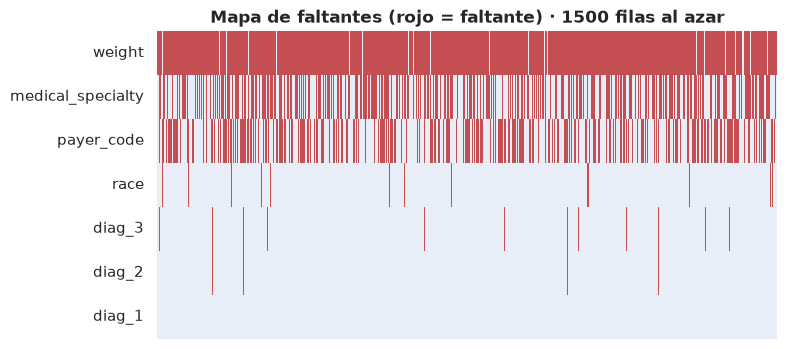

In [17]:
# Patrón de faltantes: ¿faltan juntos o por separado? (muestra para legibilidad)
cols_nulos = nulos['variable'].tolist()
fijar_tamano(8, 4)
ax = sns.heatmap(df_raw[cols_nulos].sample(1500, random_state=RANDOM_STATE).isna().astype(int).T,
                 cmap=['#e8eef7', COLOR_POS], cbar=False, xticklabels=False)
ax.set_title('Mapa de faltantes (rojo = faltante) · 1500 filas al azar');

### 5.2 Evidencia para distinguir MCAR de MAR
Para cada variable con faltantes construimos el indicador `falta = 1/0` y medimos su asociación con covariables
observadas. Se reporta el **tamaño del efecto (V de Cramér)** y no solo el p-valor: con n ≈ 100 000 cualquier
diferencia, por trivial que sea, resulta "estadísticamente significativa". Regla práctica: V < 0.1 ≈ efecto
despreciable (compatible con MCAR); V ≥ 0.1 ⇒ la falta depende de lo observado (MAR).

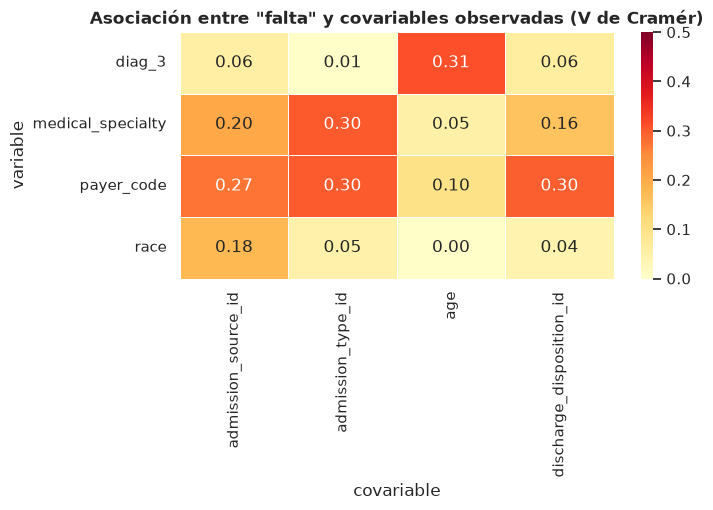

In [18]:
def evidencia_mecanismo(data: pd.DataFrame, columna: str, covariables: list[str]) -> pd.DataFrame:
    indicador = data[columna].isna().astype(int)
    filas = []
    for cov in covariables:
        tabla = pd.crosstab(indicador, data[cov].astype(str))
        p = stats.chi2_contingency(tabla).pvalue
        filas.append({'variable': columna, 'covariable': cov, 'V_cramer': cramers_v(indicador, data[cov].astype(str)),
                      'p_valor': p})
    return pd.DataFrame(filas)


covariables = ['admission_source_id', 'age', 'discharge_disposition_id', 'admission_type_id']
evidencia = pd.concat([evidencia_mecanismo(df_raw, c, covariables)
                       for c in ['race', 'payer_code', 'medical_specialty', 'diag_3']], ignore_index=True)
pivote = evidencia.pivot(index='variable', columns='covariable', values='V_cramer')
fijar_tamano(7, 3.2)
ax = sns.heatmap(pivote, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=0.5, linewidths=.5)
ax.set_title('Asociación entre "falta" y covariables observadas (V de Cramér)');

In [19]:
# Faltantes estructurales: diag_2/diag_3 faltan cuando el paciente tiene pocos diagnósticos
tabla_diag = (df_raw.assign(pocos_diag=np.where(df_raw.number_diagnoses <= 1, '≤ 1 diagnóstico', '≥ 2 diagnósticos'))
              .groupby('pocos_diag')[['diag_2', 'diag_3']].agg(lambda s: s.isna().mean() * 100).round(1))
print('% de faltantes en diag_2 / diag_3 según number_diagnoses:')
tabla_diag

% de faltantes en diag_2 / diag_3 según number_diagnoses:


,diag_2,diag_3
pocos_diag,,
≤ 1 diagnóstico,100.0,100.0
≥ 2 diagnósticos,0.1,1.2


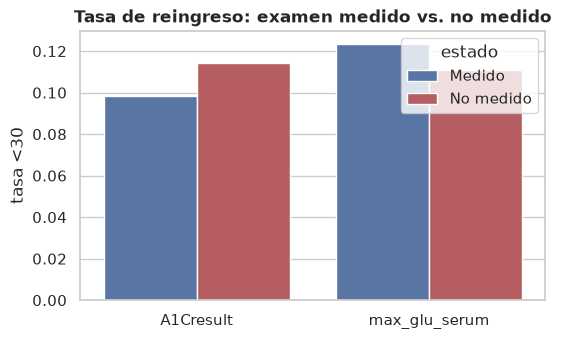

In [20]:
# Faltantes en pruebas de laboratorio: ¿el "no medido" es informativo del reingreso?
medido = (df_eda.assign(A1C_medido=np.where(df_eda.A1Cresult == 'None', 'No medido', 'Medido'),
                        glu_medido=np.where(df_eda.max_glu_serum == 'None', 'No medido', 'Medido')))
tasas_lab = pd.concat([medido.groupby('A1C_medido')['reingreso_30d'].mean().rename('A1Cresult'),
                       medido.groupby('glu_medido')['reingreso_30d'].mean().rename('max_glu_serum')], axis=1)
tasas_lab = tasas_lab.T.reset_index().melt(id_vars='index', var_name='estado', value_name='tasa')
fijar_tamano(6, 3.5)
ax = sns.barplot(data=tasas_lab, x='index', y='tasa', hue='estado', palette=[COLOR_NEG, COLOR_POS])
ax.set_title('Tasa de reingreso: examen medido vs. no medido'); ax.set_xlabel(''); ax.set_ylabel('tasa <30');

> **Lectura:** `payer_code`, `medical_specialty` y `race` muestran asociación con variables observadas (V ≥ 0.1):
> **no son MCAR**. `diag_3` falta sobre todo en pacientes jóvenes (menos comorbilidades). Para `weight` el mecanismo
> no es verificable con los datos observados (MNAR se argumenta por diseño, no se testea).
> Sobre las pruebas de laboratorio, la tasa de reingreso cambia poco entre medido y no medido (≈ 1-2 p.p.):
> el 'no medido' es sobre todo una **decisión de protocolo**, y se conserva como categoría para no perder esa información.

### 5.3 Diagnóstico y decisión por variable

| Variable | % nulo | Tipo de faltante | Evidencia | Tratamiento |
|---|---|---|---|---|
| `weight` | 96.9 % | **MNAR / por diseño** (no se registraba de forma sistemática; no verificable con los datos) | Casi vacía | **Descartar** (nada confiable que imputar) |
| `max_glu_serum`, `A1Cresult` | 94.7 % / 83.3 % | **Estructural** (el examen no se pidió) | El valor `None` es un resultado clínico | Categoría propia **"No medido"** |
| `medical_specialty` | 49.1 % | **MAR** (depende del tipo y fuente de admisión) | V ≈ 0.20-0.30 vs. `admission_source_id` / `admission_type_id` | Categoría **"Desconocido"** (no imputar con la moda: crearía 49 % de datos falsos) |
| `payer_code` | 39.6 % | MAR + variable **administrativa** | V ≈ 0.27-0.30 vs. fuente, tipo y destino al alta | **Descartar**: aporta poco clínicamente y puede introducir sesgo socioeconómico |
| `race` | 2.2 % | **MAR leve** | V ≈ 0.18 vs. fuente de admisión; ≈ 0 vs. edad | Categoría **"Desconocido"** |
| `diag_2`, `diag_3`, `diag_1` | 0.4 % / 1.4 % / 0.02 % | **Estructural** (el paciente no tiene más diagnósticos) + MAR (depende de la edad, V ≈ 0.31) | 100 % de faltantes si `number_diagnoses ≤ 1` | Categoría **"Desconocido"** |

**¿Por qué categoría propia y no imputación?** Con faltantes estructurales o MNAR, imputar (media/moda/KNN)
fabrica información que no existe y destruye la señal de "no se midió". Para MAR con muchos faltantes (≈ 50 %),
la imputación tendría más "inventado" que "observado". La categoría explícita preserva la información de ausencia.

### 5.4 Nulos encubiertos (*disguised missing values*)
El archivo `IDS_mapping.csv` documenta que algunos **códigos** son en realidad "NULL / Not Available / Not Mapped /
Unknown". El `.isna()` no los detecta porque están codificados como un número válido. Los detectamos con el
diccionario oficial en lugar de hardcodear identificadores.

In [21]:
DESCRIPCIONES_NULAS = {'NULL', 'Not Available', 'Not Mapped', 'Unknown/Invalid'}
CODIGOS_NULOS = {col: sorted(k for k, v in m.items() if v in DESCRIPCIONES_NULAS) for col, m in mapeos.items()}
CODIGOS_FALLECIDO = sorted(k for k, v in mapeos['discharge_disposition_id'].items() if v.startswith('Expired'))

encubiertos = pd.DataFrame({
    'códigos nulos': {c: v for c, v in CODIGOS_NULOS.items()},
    '% de filas': {c: round(df_raw[c].isin(v).mean() * 100, 2) for c, v in CODIGOS_NULOS.items()},
})
print(f'Códigos de alta por fallecimiento/hospicio (Expired): {CODIGOS_FALLECIDO}')
encubiertos

Códigos de alta por fallecimiento/hospicio (Expired): [11, 19, 20, 21]


,códigos nulos,% de filas
admission_type_id,"[5, 6, 8]",10.22
discharge_disposition_id,"[18, 25, 26]",4.60
admission_source_id,"[9, 15, 17, 20, 21]",6.94


> **Hallazgo:** 10 % de `admission_type_id`, 4.6 % de `discharge_disposition_id` y 6.9 % de `admission_source_id`
> son faltantes disfrazados. Si no se tratan, el modelo los interpretaría como categorías reales.

### 5.5 Consistencia lógica
Un reingreso solo es posible si el paciente sobrevivió al alta. Verificamos qué etiqueta tienen los fallecidos.

In [22]:
fallecidos = df_raw[df_raw.discharge_disposition_id.isin(CODIGOS_FALLECIDO)]
print(f'Altas por fallecimiento: {len(fallecidos):,}  →  etiquetas: {fallecidos[TARGET_ORIGINAL].value_counts().to_dict()}')
print('Todas son "NO": son negativos garantizados que no pueden reingresar y solo diluyen la clase 0.')

Altas por fallecimiento: 1,652  →  etiquetas: {'NO': 1652}
Todas son "NO": son negativos garantizados que no pueden reingresar y solo diluyen la clase 0.


## 6. Planteo del problema de ML supervisado

| Elemento | Definición |
|---|---|
| **Tipo** | Clasificación binaria |
| **Target** | `target = 1` si `readmitted == '<30'`, `0` en otro caso (`NO` o `>30`) |
| **Unidad de análisis** | Una internación de un paciente diabético |
| **Momento de predicción** | Al **alta** (solo se usan variables disponibles en ese momento) |
| **Utilidad** | Priorizar seguimiento (llamada, control ambulatorio, revisión de medicación) a pacientes de alto riesgo |
| **Métrica adecuada** | ROC-AUC, PR-AUC, recall/F1 de la clase positiva (no *accuracy*: un modelo "todos 0" obtiene ≈ 89 %) |

**¿Por qué 30 días?** Es el umbral que usan los programas de salud (p. ej. Medicare HRRP) para penalizar
reingresos potencialmente evitables; y agrupar `NO` con `>30` es clínicamente razonable (no hubo reingreso temprano).

**Variables excluidas por riesgo de *leakage*:** `readmitted` (es el target), `encounter_id` (orden temporal,
proxy de "fecha") y `patient_nbr` (identificador).

### Limitación estructural de la etiqueta: censura a la derecha
La clase `NO` mezcla "el paciente no volvió" con "no sabemos si volvió: terminó la ventana de observación".
Lo verificamos: si un encuentro **no** es el último del paciente, existe una internación posterior en el dataset.

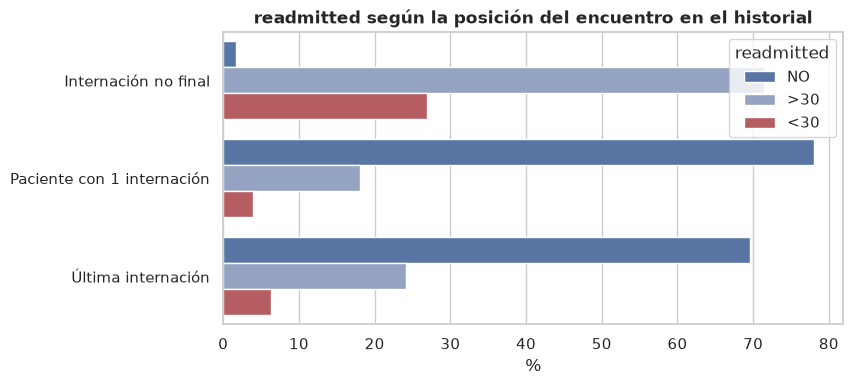

In [23]:
orden_enc = df_raw.sort_values('encounter_id').copy()   # supuesto: encounter_id crece con el tiempo
orden_enc['n_enc'] = orden_enc.groupby('patient_nbr')['encounter_id'].transform('size')
orden_enc['es_ultimo'] = orden_enc.groupby('patient_nbr').cumcount() == orden_enc['n_enc'] - 1
orden_enc['posicion'] = np.select(
    [orden_enc.n_enc == 1, orden_enc.es_ultimo],
    ['Paciente con 1 internación', 'Última internación'], default='Internación no final')

censura = (orden_enc.groupby('posicion')[TARGET_ORIGINAL].value_counts(normalize=True)
           .mul(100).rename('porcentaje').reset_index())
fijar_tamano(8, 3.8)
ax = sns.barplot(data=censura, x='porcentaje', y='posicion', hue=TARGET_ORIGINAL, hue_order=ORDEN_READMITTED,
                 palette=[COLOR_NEG, '#8DA0CB', COLOR_POS], orient='h')
ax.set_title('readmitted según la posición del encuentro en el historial'); ax.set_xlabel('%'); ax.set_ylabel('');

> **Interpretación:** en las internaciones no finales casi el 100 % está etiquetado como reingreso (la etiqueta se
> deriva *mecánicamente* de la existencia de una internación posterior). La clase 0 contiene, entonces, ruido de
> censura. Es una **limitación del dataset**, no corregible con preprocesamiento; se declara en las conclusiones.

## 7. Limpieza y feature engineering *sin estadísticos* (reglas fijas)

Se aplican **solo reglas determinísticas** que no aprenden nada de los datos (por eso pueden hacerse antes del split
sin generar leakage). Cada regla queda registrada en una tabla de auditoría con las filas/columnas afectadas.

| Regla | Justificación |
|---|---|
| R1 · Eliminar columnas constantes | Varianza 0 → no discriminan |
| R2 · Eliminar `weight` y `payer_code` | 97 % / 40 % faltante (ver 5.3) |
| R3 · Eliminar `gender = Unknown/Invalid` | Error de captura (3 filas) |
| R4 · Eliminar altas por fallecimiento | No pueden reingresar; contaminan la clase 0 |
| R5 · Nulos encubiertos → "Desconocido" | Según `IDS_mapping.csv` |
| R6 · Faltantes categóricos → categoría propia | Ver 5.3 |
| R7 · `None` en laboratorio → "No medido" | Faltante estructural |

In [24]:
def limpiar_datos(datos: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Aplica las reglas R1-R7 y devuelve (datos limpios, tabla de auditoría)."""
    out = datos.copy()
    auditoria = []

    def registrar(regla: str, detalle: str, filas_antes: int, cols_antes: int) -> None:
        auditoria.append({'regla': regla, 'detalle': detalle,
                          'filas_eliminadas': filas_antes - len(out),
                          'columnas_eliminadas': cols_antes - out.shape[1]})

    # R1: columnas constantes
    f, c = len(out), out.shape[1]
    constantes = [col for col in out.columns if out[col].nunique(dropna=False) == 1]
    out = out.drop(columns=constantes)
    registrar('R1', f'constantes: {constantes}', f, c)

    # R2: columnas con faltantes inaceptables o puramente administrativas
    f, c = len(out), out.shape[1]
    out = out.drop(columns=['weight', 'payer_code'])
    registrar('R2', 'weight, payer_code', f, c)

    # R3: género inválido
    f, c = len(out), out.shape[1]
    out = out[out['gender'] != 'Unknown/Invalid']
    registrar('R3', 'gender = Unknown/Invalid', f, c)

    # R4: fallecidos / hospicio (códigos tomados del diccionario oficial, no hardcodeados)
    f, c = len(out), out.shape[1]
    out = out[~out['discharge_disposition_id'].isin(CODIGOS_FALLECIDO)]
    registrar('R4', f'discharge_disposition_id ∈ {CODIGOS_FALLECIDO}', f, c)

    # R5: nulos encubiertos -> "Desconocido"; los códigos pasan a texto (son nominales, no numéricos)
    f, c = len(out), out.shape[1]
    for col in CODIGOS_NOMINALES:
        nulos_col = set(CODIGOS_NULOS[col])
        out[col] = out[col].map(lambda v, n=nulos_col: 'Desconocido' if v in n else str(v))
    registrar('R5', f'nulos encubiertos en {CODIGOS_NOMINALES}', f, c)

    # R6: faltantes categóricos -> categoría explícita
    f, c = len(out), out.shape[1]
    for col in ['race', 'medical_specialty'] + DIAGNOSTICOS:
        out[col] = out[col].fillna('Desconocido')
    registrar('R6', 'race, medical_specialty, diag_1..3', f, c)

    # R7: "None" en laboratorio = examen no realizado
    f, c = len(out), out.shape[1]
    for col in RESULTADOS_LAB:
        out[col] = out[col].replace({'None': 'No medido'})
    registrar('R7', 'max_glu_serum, A1Cresult: None → No medido', f, c)

    return out.reset_index(drop=True), pd.DataFrame(auditoria)


df_limpio, auditoria = limpiar_datos(df_raw)
print(f'{len(df_raw):,} → {len(df_limpio):,} filas  ({1 - len(df_limpio) / len(df_raw):.2%} descartadas)')
assert df_limpio.isna().sum().sum() == 0, 'quedaron faltantes sin tratar'
auditoria

101,766 → 100,111 filas  (1.63% descartadas)


,regla,detalle,filas_eliminadas,columnas_eliminadas
0,R1,"constantes: ['examide', 'citoglipton']",0,2
1,R2,"weight, payer_code",0,2
2,R3,gender = Unknown/Invalid,3,0
3,R4,"discharge_disposition_id ∈ [11, 19, 20, 21]",1652,0
4,R5,"nulos encubiertos en ['admission_type_id', 'di...",0,0
5,R6,"race, medical_specialty, diag_1..3",0,0
6,R7,"max_glu_serum, A1Cresult: None → No medido",0,0


### 7.1 Feature engineering (justificado)

Las nuevas variables son **funciones fila a fila** (no usan estadísticos del dataset) y se derivan de conocimiento
del dominio. Luego se **valida** si aportan información (sección 7.2).

| Feature | Construcción | Justificación |
|---|---|---|
| `diag_k_cap` | Código ICD-9 → capítulo (≈ 17 niveles) | Reduce ~700 códigos a categorías clínicamente coherentes; diabetes (250.x) se separa |
| `n_meds_activos` | # medicamentos ≠ `No` | Proxy de **complejidad terapéutica** |
| `n_meds_modificados` | # medicamentos `Up`/`Down` | Cambios de dosis = inestabilidad del control glucémico |
| `visitas_previas` | outpatient + emergency + inpatient | Carga de utilización total del sistema |
| `outpatient_nivel`, `emergency_nivel` | **Discretización** en {0, 1, 2-3, 4+} | Cero-inflados y colas extremas: el valor exacto 37 vs 40 no es informativo; los niveles son robustos a outliers |

`number_inpatient` **no** se discretiza: es el predictor individual más fuerte y agruparlo desperdicia señal.

In [25]:
CAPITULOS_ICD9 = [(1, 139, 'Infecciosas'), (140, 239, 'Neoplasias'), (240, 279, 'Endocrino-metabólicas'),
                  (280, 289, 'Sangre'), (290, 319, 'Mentales'), (320, 389, 'Nerviosas'), (390, 459, 'Circulatorio'),
                  (460, 519, 'Respiratorio'), (520, 579, 'Digestivo'), (580, 629, 'Genitourinario'),
                  (630, 679, 'Embarazo'), (680, 709, 'Piel'), (710, 739, 'Musculoesquelético'),
                  (740, 759, 'Congénitas'), (760, 779, 'Perinatal'), (780, 799, 'Síntomas mal definidos'),
                  (800, 999, 'Lesiones')]
NIVELES_VISITAS = ['0', '1', '2-3', '4+']


def agrupar_icd9(codigos: pd.Series) -> pd.Series:
    """Mapea códigos ICD-9-CM a su capítulo. 250.x → 'Diabetes'; V.. y E.. tienen capítulos propios."""
    texto = codigos.astype(str)
    numero = pd.to_numeric(texto.str.extract(r'^(\d+)')[0], errors='coerce')
    capitulo = pd.Series('Otro', index=codigos.index)
    for inferior, superior, nombre in CAPITULOS_ICD9:
        capitulo[(numero >= inferior) & (numero <= superior)] = nombre
    capitulo[texto.str.startswith('250')] = 'Diabetes'
    capitulo[texto.str.startswith('V')] = 'Factores de contacto (V)'
    capitulo[texto.str.startswith('E')] = 'Causas externas (E)'
    capitulo[texto == 'Desconocido'] = 'Desconocido'
    return capitulo


def discretizar_visitas(serie: pd.Series) -> pd.Series:
    return pd.cut(serie, bins=[-1, 0, 1, 3, np.inf], labels=NIVELES_VISITAS).astype(str)


def ingenieria_de_features(datos: pd.DataFrame) -> pd.DataFrame:
    """Crea features derivadas por fila (sin estadísticos globales) y elimina las fuentes redundantes."""
    out = datos.copy()
    for col in DIAGNOSTICOS:
        out[f'{col}_cap'] = agrupar_icd9(out[col])
    meds = [m for m in MEDICAMENTOS if m in out.columns]      # R1 ya eliminó las constantes
    out['n_meds_activos'] = out[meds].ne('No').sum(axis=1)
    out['n_meds_modificados'] = out[meds].isin(['Up', 'Down']).sum(axis=1)
    out['visitas_previas'] = out[['number_outpatient', 'number_emergency', 'number_inpatient']].sum(axis=1)
    out['outpatient_nivel'] = discretizar_visitas(out['number_outpatient'])
    out['emergency_nivel'] = discretizar_visitas(out['number_emergency'])
    out['target'] = (out[TARGET_ORIGINAL] == '<30').astype(int)
    return out.drop(columns=DIAGNOSTICOS + ['number_outpatient', 'number_emergency'])


df_fe = ingenieria_de_features(df_limpio)
print('Capítulos ICD-9 en diag_1:'); print(df_fe['diag_1_cap'].value_counts().to_string())

Capítulos ICD-9 en diag_1:
diag_1_cap
Circulatorio                29781
Respiratorio                10058
Digestivo                    9115
Diabetes                     8693
Síntomas mal definidos       7618
Lesiones                     6879
Genitourinario               5015
Musculoesquelético           4944
Neoplasias                   3299
Endocrino-metabólicas        2668
Infecciosas                  2585
Piel                         2513
Mentales                     2259
Factores de contacto (V)     1638
Nerviosas                    1192
Sangre                       1095
Embarazo                      687
Congénitas                     50
Desconocido                    21
Causas externas (E)             1


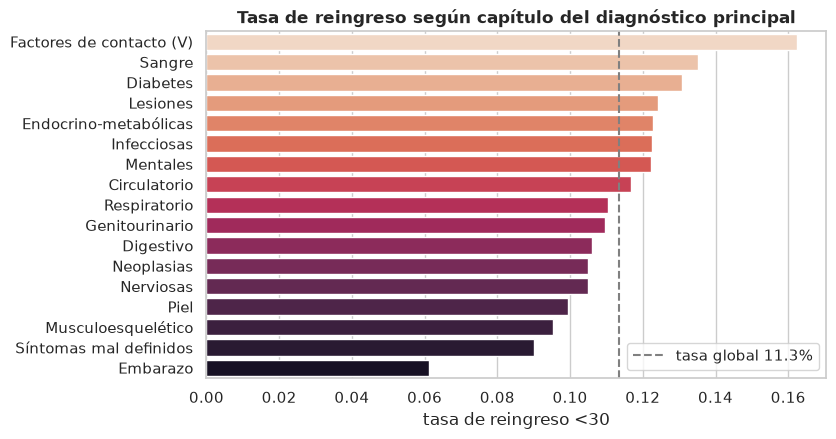

In [26]:
fijar_tamano(8, 4.5)
grafico_tasa(df_fe.assign(reingreso_30d=df_fe['target']), 'diag_1_cap', min_n=200,
             titulo='Tasa de reingreso según capítulo del diagnóstico principal');

## 8. Split train/test **agrupado por paciente**

**Problema:** el 23 % de los pacientes tiene más de una internación (≈ 46 % de las filas). Con un split aleatorio
por fila, un mismo paciente caería en train y test; el modelo "reconocería" al paciente y el test sería
optimista (fuga por identidad).

**Alternativas evaluadas**
1. *Deduplicar* (un encuentro por paciente): evita la fuga pero descarta ~30 % de las filas y ~45 % de los positivos
   (los reingresos se concentran en pacientes con varias internaciones) → sesgo de selección.
2. **`StratifiedGroupKFold`** (elegida): ningún paciente cruza el límite **y** conserva todas las filas **y**
   mantiene la proporción de la clase positiva (estratificación).

Se toma el primer fold de 5 como test (80 / 20) con semilla fija.

In [27]:
sgkf = StratifiedGroupKFold(n_splits=TEST_SIZE_FOLDS, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_test = next(sgkf.split(df_fe, df_fe['target'], groups=df_fe['patient_nbr']))

COLUMNAS_NO_FEATURES = ['target', TARGET_ORIGINAL, 'encounter_id', 'patient_nbr']
train, test = df_fe.iloc[idx_train].reset_index(drop=True), df_fe.iloc[idx_test].reset_index(drop=True)
X_train, y_train = train.drop(columns=COLUMNAS_NO_FEATURES), train['target']
X_test, y_test = test.drop(columns=COLUMNAS_NO_FEATURES), test['target']
grupos_train, grupos_test = train['patient_nbr'], test['patient_nbr']

# Verificaciones duras: si fallan, el notebook se detiene
assert len(train) + len(test) == len(df_fe), 'el split perdió filas'
assert set(grupos_train).isdisjoint(grupos_test), 'hay pacientes en train y test'

balance = pd.DataFrame({'filas': [len(df_fe), len(train), len(test)],
                        'positivos': [df_fe.target.sum(), y_train.sum(), y_test.sum()],
                        '% positivos': [df_fe.target.mean() * 100, y_train.mean() * 100, y_test.mean() * 100]},
                       index=['Total', 'Train', 'Test']).round(2)
balance

,filas,positivos,% positivos
Total,100111,11357,11.34
Train,80088,9085,11.34
Test,20023,2272,11.35


> Train y test conservan la misma prevalencia (≈ 11.3 %), por lo que las métricas serán comparables.
> **De acá en adelante, todo se *aprende* únicamente con `X_train`.**

## 9. Outliers: detección **y** tratamiento (solo con train)

### Detección
* **Regla IQR de Tukey** (`Q1 − 1.5·IQR`, `Q3 + 1.5·IQR`): no asume normalidad, adecuada para distribuciones asimétricas.
* No usamos *z-score*: asume simetría y la media/desvío ya están distorsionados por los propios outliers.

### Tratamiento
Los valores extremos acá son **conteos reales** (un paciente con 25 visitas de emergencia existe), no errores de
carga. Eliminarlos descartaría justamente a los pacientes más graves. Estrategia:
1. **Winsorización** a los percentiles 1 y 99 (aprendidos en train): limita la influencia de los extremos sin borrar filas.
2. **`log1p`** sobre variables con asimetría > 1 *después* de winsorizar: comprime la cola derecha y acerca la
   distribución a la simetría que asumen los modelos lineales y el PCA.

In [28]:
NUMERICAS = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
             'number_inpatient', 'number_diagnoses', 'n_meds_activos', 'n_meds_modificados', 'visitas_previas']


def resumen_iqr(serie: pd.Series) -> pd.Series:
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    limite_sup = q3 + 1.5 * iqr
    es_outlier = (serie < q1 - 1.5 * iqr) | (serie > limite_sup)
    return pd.Series({'Q1': q1, 'mediana': serie.median(), 'Q3': q3, 'p99': serie.quantile(.99), 'max': serie.max(),
                      'límite_IQR': limite_sup, '%_outliers': es_outlier.mean() * 100, 'asimetría': serie.skew()})


outliers_train = X_train[NUMERICAS].apply(resumen_iqr).T.round(2)
outliers_train

,Q1,mediana,Q3,p99,max,límite_IQR,%_outliers,asimetría
time_in_hospital,2.0,4.0,6.0,14.0,14.0,12.0,2.18,1.14
num_lab_procedures,31.0,44.0,57.0,84.0,132.0,96.0,0.12,-0.25
num_procedures,0.0,1.0,2.0,6.0,6.0,5.0,4.79,1.32
num_medications,10.0,15.0,20.0,43.0,81.0,35.0,2.52,1.32
number_inpatient,0.0,0.0,1.0,6.0,21.0,2.5,6.90,3.73
number_diagnoses,6.0,8.0,9.0,9.0,16.0,13.5,0.28,-0.87
n_meds_activos,1.0,1.0,2.0,4.0,6.0,3.5,1.36,0.68
n_meds_modificados,0.0,0.0,1.0,2.0,4.0,2.5,0.11,1.42
visitas_previas,0.0,0.0,2.0,11.0,80.0,5.0,4.44,5.55


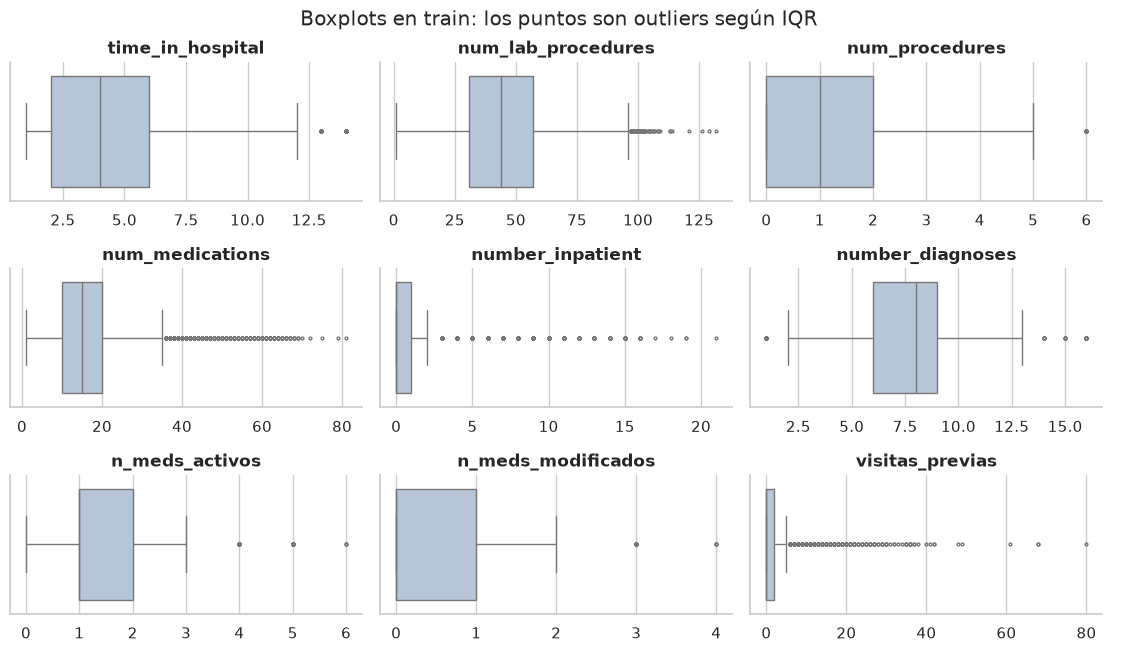

In [29]:
largo_train = X_train[NUMERICAS].melt(var_name='variable', value_name='valor')
g = sns.catplot(data=largo_train, x='valor', col='variable', col_wrap=3, kind='box', orient='h',
                color='lightsteelblue', sharex=False, height=2.2, aspect=1.7, fliersize=2)
g.set_titles('{col_name}'); g.set_xlabels('')
g.figure.suptitle('Boxplots en train: los puntos son outliers según IQR', y=1.02);

> **Interpretación:** `number_inpatient` (≈ 7 %), `num_procedures` (≈ 5 %) y `visitas_previas` (≈ 4 %) concentran la mayor
> proporción de outliers; `visitas_previas` llega a 80 con un p99 de 11 (cola muy larga). `number_diagnoses` y
> `num_lab_procedures` casi no tienen. Ahora mostramos el efecto de winsorizar y decidimos qué variables reciben `log1p`.

In [30]:
p_inf, p_sup = PERCENTILES_WINSOR
limites = X_train[NUMERICAS].quantile([p_inf, p_sup])
winsorizadas = X_train[NUMERICAS].clip(lower=limites.loc[p_inf], upper=limites.loc[p_sup], axis=1)

asimetria = pd.DataFrame({'original': X_train[NUMERICAS].skew(), 'winsorizada': winsorizadas.skew(),
                          'winsor + log1p': np.log1p(winsorizadas).skew()}).round(2)
COLS_LOG = asimetria.index[asimetria['winsorizada'].abs() > 1].tolist()   # regla: |skew| > 1 tras winsorizar
COLS_LINEALES = [c for c in NUMERICAS if c not in COLS_LOG]
print(f'Reciben log1p (|skew| > 1 tras winsorizar): {COLS_LOG}')
asimetria

Reciben log1p (|skew| > 1 tras winsorizar): ['time_in_hospital', 'num_procedures', 'number_inpatient', 'n_meds_modificados', 'visitas_previas']


,original,winsorizada,winsor + log1p
time_in_hospital,1.14,1.14,0.10
num_lab_procedures,-0.25,-0.30,-2.23
num_procedures,1.32,1.32,0.52
num_medications,1.32,0.98,-0.37
number_inpatient,3.73,2.50,1.36
number_diagnoses,-0.87,-0.91,-1.38
n_meds_activos,0.68,0.65,-0.27
n_meds_modificados,1.42,1.32,1.12
visitas_previas,5.55,2.60,1.04


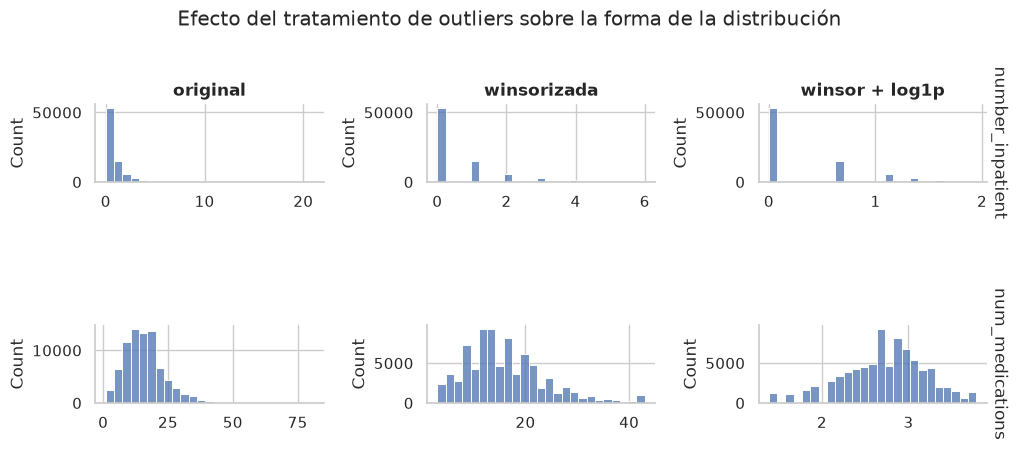

In [31]:
antes_despues = pd.concat([
    X_train[['number_inpatient', 'num_medications']].assign(etapa='original'),
    winsorizadas[['number_inpatient', 'num_medications']].assign(etapa='winsorizada'),
    np.log1p(winsorizadas[['number_inpatient', 'num_medications']]).assign(etapa='winsor + log1p'),
]).melt(id_vars='etapa', var_name='variable', value_name='valor')
g = sns.FacetGrid(antes_despues, col='etapa', row='variable', sharex=False, sharey=False,
                  height=2.3, aspect=1.5, margin_titles=True)
g.map_dataframe(sns.histplot, x='valor', bins=25, color=COLOR_NEG)
g.set_titles(col_template='{col_name}', row_template='{row_name}')
g.set_xlabels('')
g.figure.suptitle('Efecto del tratamiento de outliers sobre la forma de la distribución', y=1.03);

## 10. Pipeline de preprocesamiento (codificación, discretización, escalado)

Todo se encapsula en un `Pipeline` de scikit-learn. Ventajas frente a funciones sueltas:
* `fit` se llama **una sola vez con train**; `transform` aplica los mismos parámetros a cualquier dato nuevo.
* Es **reproducible y serializable**: el mismo objeto sirve para producción.
* Evita errores de desalineación de columnas entre train y test.

| Bloque | Variables | Técnica | Justificación teórica |
|---|---|---|---|
| Numéricas asimétricas | `COLS_LOG` | Winsor → `log1p` → `StandardScaler` | Estabiliza varianza y cola |
| Numéricas simétricas | `COLS_LINEALES` | Winsor → `StandardScaler` | Misma escala (media 0, desvío 1): necesario para regularización L1/L2, PCA y modelos basados en distancia |
| Ordinales | `age`, niveles de visitas | `OrdinalEncoder` con orden explícito → escalado | Conserva el **orden**; one-hot lo perdería y sumaría columnas |
| Nominales | resto | `OneHotEncoder(drop='first', min_frequency=1 %)` | No impone un orden falso; `drop='first'` evita la **trampa de la variable dummy** (colinealidad perfecta); categorías raras se agrupan para limitar la dimensión y el sobreajuste |

**Medicamentos:** se codifican como **nominales** (no como ordinal `No<Down<Steady<Up`): "Down" y "Up" son
*direcciones* de cambio, no magnitudes ordenadas.

In [32]:
class Winsorizador(BaseEstimator, TransformerMixin):
    """Recorta cada columna a los percentiles [p_inf, p_sup] **aprendidos en fit** (solo train)."""

    def __init__(self, p_inf: float = 0.01, p_sup: float = 0.99):
        self.p_inf, self.p_sup = p_inf, p_sup

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(getattr(X, 'columns', range(np.shape(X)[1])), dtype=object)
        X = np.asarray(X, dtype=float)
        self.inferior_ = np.quantile(X, self.p_inf, axis=0)
        self.superior_ = np.quantile(X, self.p_sup, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.inferior_, self.superior_)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_ if input_features is None else np.asarray(input_features, dtype=object)


class FiltroCorrelacion(BaseEstimator, TransformerMixin):
    """Elimina, de cada par con |correlación| > umbral, la columna que aparece después.
    El criterio se aprende en fit (train) y se reaplica idéntico en transform."""

    def __init__(self, umbral: float = 0.90):
        self.umbral = umbral

    def fit(self, X: pd.DataFrame, y=None):
        corr = X.corr().abs()
        superior = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
        self.eliminar_ = [c for c in superior.columns if (superior[c] > self.umbral).any()]
        self.columnas_ = [c for c in X.columns if c not in self.eliminar_]
        return self

    def transform(self, X: pd.DataFrame):
        return X[self.columnas_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columnas_, dtype=object)


NIVELES_EDAD = [ORDEN_EDAD]
ORDINALES = ['age', 'outpatient_nivel', 'emergency_nivel']
MEDS_VARIABLES = [m for m in MEDICAMENTOS if m in X_train.columns]      # sin las constantes eliminadas en R1
NOMINALES = (['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
              'medical_specialty', 'diag_1_cap', 'diag_2_cap', 'diag_3_cap', 'change', 'diabetesMed',
              'max_glu_serum', 'A1Cresult'] + MEDS_VARIABLES)


def construir_pipeline(cols_log: list[str], cols_lineales: list[str]) -> Pipeline:
    """Preprocesamiento completo: transformación por bloques → filtro de varianza → filtro de correlación."""
    bloque_log = Pipeline([('winsor', Winsorizador(*PERCENTILES_WINSOR)),
                           ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                           ('escala', StandardScaler())])
    bloque_lineal = Pipeline([('winsor', Winsorizador(*PERCENTILES_WINSOR)), ('escala', StandardScaler())])
    bloque_ordinal = Pipeline([
        ('codigo', OrdinalEncoder(categories=[ORDEN_EDAD, NIVELES_VISITAS, NIVELES_VISITAS],
                                  handle_unknown='use_encoded_value', unknown_value=-1)),
        ('escala', StandardScaler())])
    bloque_nominal = OneHotEncoder(drop='first', min_frequency=FRECUENCIA_MINIMA, sparse_output=False,
                                   handle_unknown='infrequent_if_exist')

    transformador = ColumnTransformer([('log', bloque_log, cols_log),
                                       ('lineal', bloque_lineal, cols_lineales),
                                       ('ordinal', bloque_ordinal, ORDINALES),
                                       ('nominal', bloque_nominal, NOMINALES)],
                                      verbose_feature_names_out=False)
    pipeline = Pipeline([
        ('transformacion', transformador),
        # quasi-constantes: una dummy con p(1-p) < 0.005·0.995 está activa en < 0.5 % de las filas
        ('varianza', VarianceThreshold(threshold=0.005 * (1 - 0.005))),
        ('correlacion', FiltroCorrelacion(UMBRAL_CORRELACION)),
    ])
    return pipeline.set_output(transform='pandas')


# Todas las columnas de X_train deben estar asignadas a exactamente un bloque (o descartadas a propósito)
asignadas = COLS_LOG + COLS_LINEALES + ORDINALES + NOMINALES
sin_asignar = sorted(set(X_train.columns) - set(asignadas))
assert not sin_asignar, f'columnas sin asignar al pipeline: {sin_asignar}'
assert len(asignadas) == len(set(asignadas)), 'hay columnas asignadas a dos bloques'

# Aviso esperado: categorías muy raras (p. ej. un código ICD-9 puntual) que aparecen en test pero no en train.
# `handle_unknown='infrequent_if_exist'` las codifica como "todo ceros": es el comportamiento deseado en producción.
warnings.filterwarnings('ignore', message='Found unknown categories')

pipeline = construir_pipeline(COLS_LOG, COLS_LINEALES)
Xtr = pipeline.fit_transform(X_train, y_train)     # fit SOLO con train
Xte = pipeline.transform(X_test)                   # test: solo transform
print(f'Train: {Xtr.shape} | Test: {Xte.shape}')
print(f'Columnas tras codificar:  {len(pipeline["transformacion"].get_feature_names_out())}')
print(f'Tras filtro de varianza:  {pipeline["varianza"].get_feature_names_out().size}')
print(f'Tras filtro de correlación: {Xtr.shape[1]}  (eliminadas por redundancia: {pipeline["correlacion"].eliminar_})')

Train: (80088, 118) | Test: (20023, 118)
Columnas tras codificar:  132
Tras filtro de varianza:  118
Tras filtro de correlación: 118  (eliminadas por redundancia: [])


In [33]:
# Verificación: las numéricas quedaron estandarizadas con parámetros de train
cols_escaladas = [c for c in COLS_LOG + COLS_LINEALES + ORDINALES if c in Xtr.columns]
verificacion = pd.DataFrame({'media_train': Xtr[cols_escaladas].mean(), 'desvio_train': Xtr[cols_escaladas].std(),
                             'media_test': Xte[cols_escaladas].mean(), 'desvio_test': Xte[cols_escaladas].std()}).round(3)
verificacion

,media_train,desvio_train,media_test,desvio_test
time_in_hospital,-0.0,1.0,-0.002,1.001
num_procedures,-0.0,1.0,-0.006,1.001
number_inpatient,-0.0,1.0,0.007,0.998
n_meds_modificados,0.0,1.0,-0.003,0.999
visitas_previas,0.0,1.0,0.005,0.990
num_lab_procedures,0.0,1.0,-0.009,1.003
num_medications,0.0,1.0,-0.006,0.990
number_diagnoses,0.0,1.0,0.003,1.000
n_meds_activos,-0.0,1.0,0.013,1.008
age,0.0,1.0,-0.004,1.001


> Train tiene media 0 / desvío 1 (por construcción). En **test** los valores se acercan a 0/1 **sin ser exactos**:
> es lo correcto, porque se escala con los parámetros de train. Si en test dieran exactamente 0 y 1 habría leakage.

## 11. Balance de clases

### Diagnóstico
Proporción ≈ 1 : 7.8 (≈ 11.3 % positivos). Efectos del desbalance: la pérdida se minimiza prediciendo casi siempre
la clase mayoritaria y la *accuracy* resulta engañosa.

Ratio de desbalance en train: 7.8 : 1


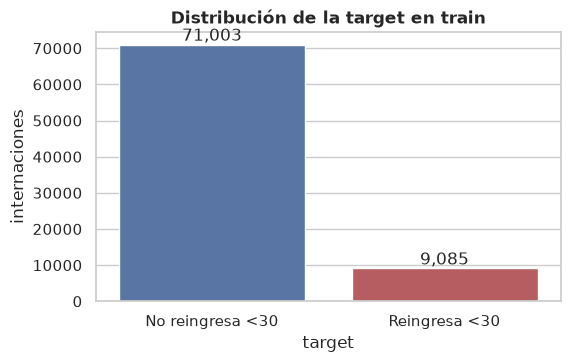

In [34]:
conteo = y_train.value_counts().sort_index().rename({0: 'No reingresa <30', 1: 'Reingresa <30'})
print(f'Ratio de desbalance en train: {conteo.iloc[0] / conteo.iloc[1]:.1f} : 1')
fijar_tamano(6, 3.5)
ax = sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, palette=[COLOR_NEG, COLOR_POS], legend=False)
for cont in ax.containers:
    ax.bar_label(cont, fmt='{:,.0f}')
ax.set_title('Distribución de la target en train'); ax.set_ylabel('internaciones');

### Mecanismos evaluados y decisión
| Técnica | Cómo funciona | Pros | Contras / por qué sí o no |
|---|---|---|---|
| **`class_weight='balanced'`** | Pondera la pérdida por `n / (k·n_clase)` | Sin modificar los datos, sin perder ni inventar filas | Requiere modelos que lo soporten ✔ |
| **Submuestreo aleatorio** (*undersampling*) | Descarta negativos hasta igualar | Simple, rápido | Pierde ≈ 87 % de los negativos (información) |
| **SMOTE** | Interpola vecinos de la clase minoritaria | Popular | Interpolar sobre one-hot genera puntos **no válidos** (0.37 de "género") y sobre nominales densas es poco confiable → *no recomendable en esta matriz* |

**Decisión:** `class_weight='balanced'` como mecanismo principal (no altera los datos) y se **materializa** además
un conjunto submuestreado de train para comparar. **Nunca** se balancea el test: debe reflejar la prevalencia real.

In [35]:
def submuestreo_aleatorio(X: pd.DataFrame, y: pd.Series, semilla: int = RANDOM_STATE) -> tuple[pd.DataFrame, pd.Series]:
    """Iguala la clase mayoritaria a la minoritaria descartando negativos al azar."""
    rng = np.random.default_rng(semilla)
    pos = np.flatnonzero(y.to_numpy() == 1)
    neg = rng.choice(np.flatnonzero(y.to_numpy() == 0), size=len(pos), replace=False)
    idx = np.sort(np.concatenate([pos, neg]))
    return X.iloc[idx].reset_index(drop=True), y.iloc[idx].reset_index(drop=True)


Xtr_bal, ytr_bal = submuestreo_aleatorio(Xtr, y_train)
comparacion = pd.DataFrame({'Original': y_train.value_counts(), 'Submuestreado': ytr_bal.value_counts()}).T
comparacion.columns = ['No reingresa', 'Reingresa']
print('Conjunto balanceado (solo train):'); comparacion

Conjunto balanceado (solo train):


,No reingresa,Reingresa
Original,71003,9085
Submuestreado,9085,9085


## 12. Selección de features

Se combinan tres criterios (filtros, independientes del modelo) y se **aplican** dentro del pipeline:

1. **Varianza casi nula** — una columna que casi no varía no discrimina (`VarianceThreshold`).
2. **Redundancia** — de dos features con |ρ| > 0.90 se conserva una (`FiltroCorrelacion`); mantener ambas
   aporta colinealidad sin información nueva.
3. **Relevancia** — **información mutua** con la target. A diferencia de la correlación, captura relaciones
   **no lineales** y es válida para variables mixtas (binarias y continuas). Se usa para *interpretar* y priorizar.

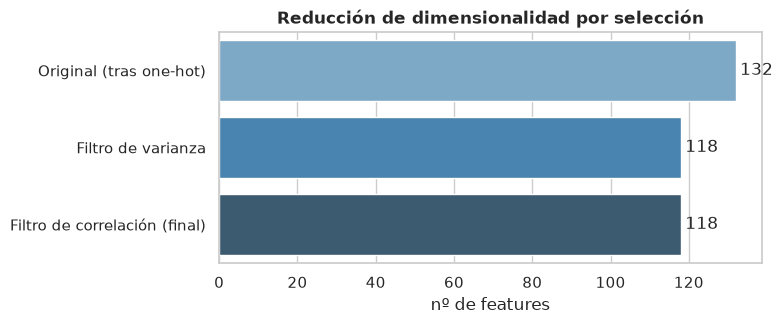

In [36]:
resumen_seleccion = pd.DataFrame({
    'etapa': ['Original (tras one-hot)', 'Filtro de varianza', 'Filtro de correlación (final)'],
    'n_features': [len(pipeline['transformacion'].get_feature_names_out()),
                   pipeline['varianza'].get_feature_names_out().size, Xtr.shape[1]]})
fijar_tamano(7, 3)
ax = sns.barplot(data=resumen_seleccion, x='n_features', y='etapa', hue='etapa', legend=False, palette='Blues_d', orient='h')
for cont in ax.containers:
    ax.bar_label(cont, padding=3)
ax.set_title('Reducción de dimensionalidad por selección'); ax.set_ylabel(''); ax.set_xlabel('nº de features');

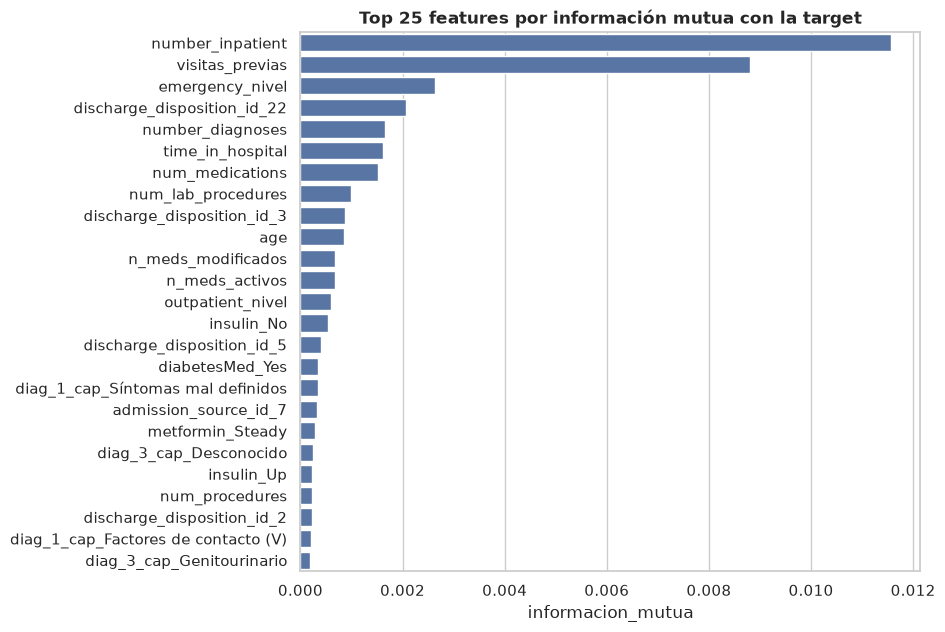

In [37]:
# Información mutua. Todas las columnas toman pocos valores distintos (dummies, conteos, niveles ordinales), por lo que
# se tratan como discretas: así todas usan el mismo estimador y los valores son comparables entre sí
# (mezclar el estimador discreto con el de k-vecinos para continuas produce escalas distintas).
# (la MI es invariante a renombrar los valores, así que se recodifican como enteros 0..k-1)
Xtr_codigos = Xtr.apply(lambda col: pd.factorize(col)[0])
mi = pd.Series(mutual_info_classif(Xtr_codigos, y_train, discrete_features=True, random_state=RANDOM_STATE),
               index=Xtr.columns).sort_values(ascending=False)
top_mi = mi.head(25).reset_index()
top_mi.columns = ['feature', 'informacion_mutua']
fijar_tamano(8, 7)
ax = sns.barplot(data=top_mi, x='informacion_mutua', y='feature', color=COLOR_NEG, orient='h')
ax.set_title('Top 25 features por información mutua con la target'); ax.set_ylabel('');

> **Interpretación:** las variables más informativas son el **historial de utilización** (`number_inpatient`,
> `visitas_previas`, `emergency_nivel`), el **destino al alta** (código 22 = rehabilitación) y la **carga clínica**
> (`number_diagnoses`, `time_in_hospital`, `num_medications`). Los valores son bajos en términos absolutos
> (consistente con una señal débil y distribuida). Entre las features **derivadas**, `visitas_previas` y
> `emergency_nivel` quedan en el top 3; `n_meds_activos`/`n_meds_modificados`/`outpatient_nivel` aportan poco
> (puestos ≈ 11-13 de 118): se conservan por ser baratas y clínicamente interpretables, pero no son decisivas.
>
> Nota: al codificar, las categorías con < 1 % de frecuencia se agruparon como `*_infrequent_sklearn`; las que
> quedaron casi siempre en cero (< 0.5 %) las eliminó el filtro de varianza.

In [38]:
derivadas = ['visitas_previas', 'n_meds_activos', 'n_meds_modificados', 'outpatient_nivel', 'emergency_nivel']
validacion = pd.DataFrame({'MI': mi.reindex(derivadas), 'puesto_en_ranking': [list(mi.index).index(c) + 1 if c in mi.index else np.nan
                                                                              for c in derivadas]})
print(f'Posición entre {len(mi)} features (1 = más informativa):')
validacion.round(4)

Posición entre 118 features (1 = más informativa):


,MI,puesto_en_ranking
visitas_previas,0.0088,2
n_meds_activos,0.0007,12
n_meds_modificados,0.0007,11
outpatient_nivel,0.0006,13
emergency_nivel,0.0026,3


## 13. Reducción de dimensionalidad: PCA

**Qué hace:** proyecta los datos sobre direcciones ortogonales (componentes) que maximizan la **varianza** explicada.
Requiere variables **centradas y en la misma escala** (se estandarizan con parámetros de train) y se ajusta **solo con train**.

**Advertencia metodológica:** PCA es **no supervisado**: maximiza varianza, no capacidad de separar clases. Además
asume relaciones lineales y variables continuas; sobre dummies binarias es solo una aproximación.

{'80%': '74 componentes (63% de las 118 features)', '90%': '88 componentes (75% de las 118 features)', '95%': '97 componentes (82% de las 118 features)'}


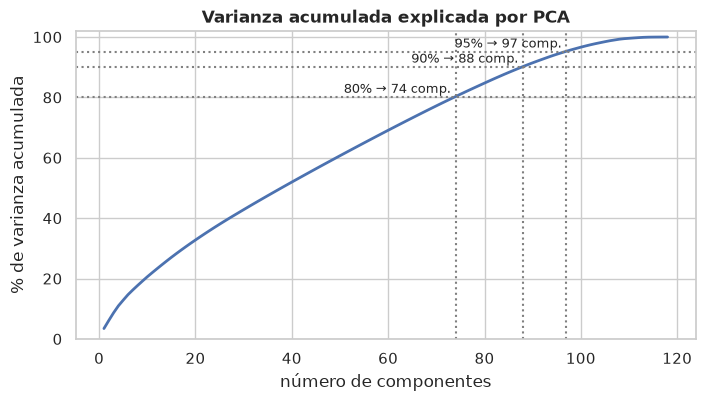

In [39]:
# Las dummies conservan su escala 0/1 (varianza p(1-p) << 1) mientras las numéricas tienen varianza 1:
# sin estandarizar, PCA estaría dominado por las numéricas. Se estandariza todo ("PCA sobre correlaciones").
escalador_pca = StandardScaler().fit(Xtr)
Ztr, Zte = escalador_pca.transform(Xtr), escalador_pca.transform(Xte)
pca = PCA(random_state=RANDOM_STATE).fit(Ztr)
varianza = pd.DataFrame({'componente': np.arange(1, len(pca.explained_variance_ratio_) + 1),
                         'individual': pca.explained_variance_ratio_ * 100,
                         'acumulada': pca.explained_variance_ratio_.cumsum() * 100})
UMBRALES_PCA = {u: int(np.searchsorted(varianza['acumulada'], u) + 1) for u in (80, 90, 95)}
print({f'{u}%': f'{k} componentes ({k / Xtr.shape[1]:.0%} de las {Xtr.shape[1]} features)' for u, k in UMBRALES_PCA.items()})

fijar_tamano(8, 4)
ax = sns.lineplot(data=varianza, x='componente', y='acumulada', color=COLOR_NEG, lw=2)
for umbral, k in UMBRALES_PCA.items():
    ax.axhline(umbral, ls=':', color='gray'); ax.axvline(k, ls=':', color='gray')
    ax.text(k - 1, umbral + 1.5, f'{umbral}% → {k} comp.', fontsize=9, ha='right')
ax.set_title('Varianza acumulada explicada por PCA')
ax.set_xlabel('número de componentes'); ax.set_ylabel('% de varianza acumulada'); ax.set_ylim(0, 102);

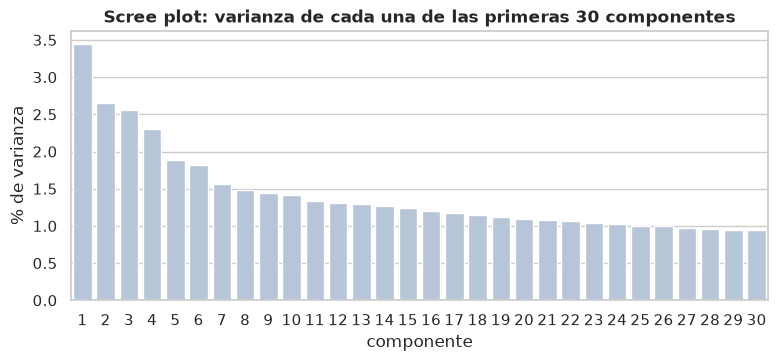

In [40]:
fijar_tamano(9, 3.5)
ax = sns.barplot(data=varianza.head(30), x='componente', y='individual', color='lightsteelblue')
ax.set_title('Scree plot: varianza de cada una de las primeras 30 componentes')
ax.set_xlabel('componente'); ax.set_ylabel('% de varianza');

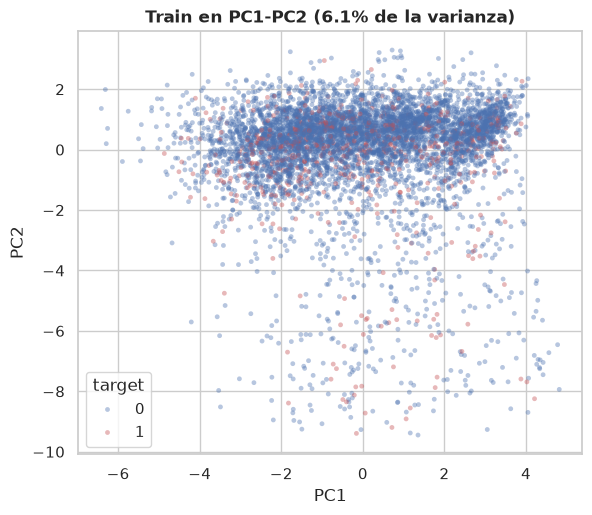

In [41]:
# Proyección 2D coloreada por la target (muestra para legibilidad)
proyeccion = pd.DataFrame(pca.transform(Ztr)[:, :2], columns=['PC1', 'PC2']).assign(target=y_train.to_numpy())
muestra = proyeccion.sample(6000, random_state=RANDOM_STATE)
fijar_tamano(6.5, 5.5)
ax = sns.scatterplot(data=muestra, x='PC1', y='PC2', hue='target', palette=PALETA_TARGET, s=12, alpha=.4, linewidth=0)
ax.set_title(f'Train en PC1-PC2 ({pca.explained_variance_ratio_[:2].sum():.1%} de la varianza)');

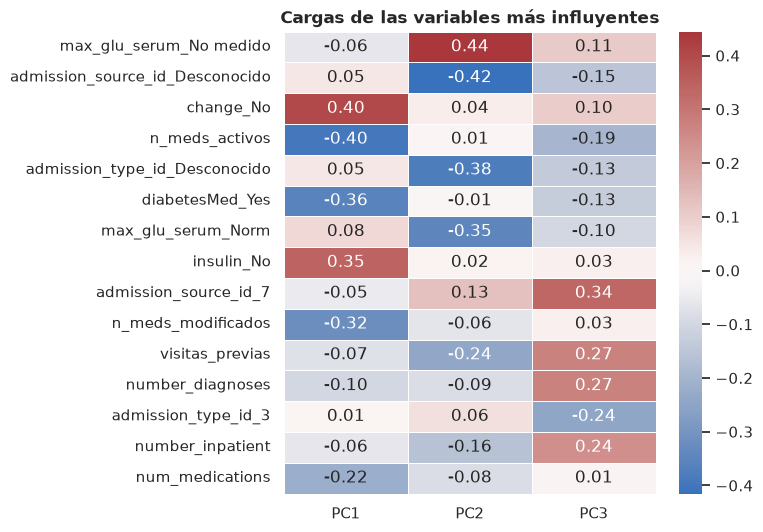

In [42]:
# ¿Qué variables componen las primeras componentes?
cargas = pd.DataFrame(pca.components_[:3].T, index=Xtr.columns, columns=['PC1', 'PC2', 'PC3'])
cargas_top = (cargas.abs().max(axis=1).sort_values(ascending=False).head(15).index)
fijar_tamano(6, 6)
ax = sns.heatmap(cargas.loc[cargas_top], annot=True, fmt='.2f', cmap='vlag', center=0, linewidths=.5)
ax.set_title('Cargas de las variables más influyentes');

### Ventajas y desventajas (con evidencia de este dataset)

| | Evaluación |
|---|---|
| ✔ **Ventaja** | Reduce dimensionalidad y elimina colinealidad: las componentes son ortogonales |
| ✔ **Ventaja** | Útil para visualización y para modelos sensibles a la dimensión (kNN, SVM con kernel RBF) |
| ✘ **Desventaja** | **Pérdida de interpretabilidad**: una componente mezcla decenas de variables clínicas; ya no se puede decir "el historial de internaciones aumenta el riesgo" |
| ✘ **Desventaja** | Con *one-hot*, la varianza se reparte casi uniforme: hacen falta muchas componentes (ver umbrales arriba) → **la ganancia de compresión es modesta** |
| ✘ **Desventaja** | Es no supervisado: las 2 primeras componentes **no separan** las clases (nube superpuesta); la señal de reingreso está en direcciones de baja varianza |

**Conclusión:** para este problema, la **selección de features** (sección 12) es preferible a PCA: reduce columnas
conservando interpretabilidad. PCA se deja como alternativa evaluable (sección 15: `LogReg + PCA 90 %`).

## 14. Pruebas de aptitud: ¿el dataset procesado sirve para entrenar un modelo?

Una cosa es que el código corra y otra que la matriz sea **válida estadísticamente**. Se ejecutan tres grupos de pruebas.
Las de los grupos A y B son *aserciones*: si una falla, el notebook se detiene.

### A. Pruebas estructurales (la matriz es aceptable para cualquier algoritmo)

In [43]:
def verificar_matriz(Xa, ya, Xb, yb, g_a, g_b) -> pd.DataFrame:
    """Chequeos de contrato de la matriz final. Devuelve la tabla de resultados y falla si algo no se cumple."""
    n_pos, n_feat = int(ya.sum()), Xa.shape[1]
    prohibidas = {'target', 'readmitted', 'encounter_id', 'patient_nbr'}
    auc_univariada = Xa.apply(lambda col: roc_auc_score(ya, col))
    fuga_max = float((auc_univariada - 0.5).abs().max() * 2)
    rango = np.linalg.matrix_rank(Xa.sample(min(5000, len(Xa)), random_state=RANDOM_STATE).to_numpy(dtype=float))
    n_rango = min(5000, len(Xa))

    chequeos = [
        ('Sin NaN ni inf (train y test)',
         bool(np.isfinite(Xa.to_numpy(float)).all() and np.isfinite(Xb.to_numpy(float)).all()),
         'matriz completamente numérica y finita'),
        ('Todas las columnas son numéricas', bool(all(pd.api.types.is_numeric_dtype(t) for t in Xa.dtypes)), ''),
        ('Train y test tienen las mismas columnas y orden', list(Xa.columns) == list(Xb.columns), f'{n_feat} columnas'),
        ('Sin columnas duplicadas', len({Xa[c].to_numpy().tobytes() for c in Xa.columns}) == n_feat, ''),
        ('Sin columnas constantes en train', bool((Xa.std() > 0).all()), ''),
        ('Sin identificadores ni target entre las features', prohibidas.isdisjoint(Xa.columns), ''),
        ('Ningún paciente en train y test', set(g_a).isdisjoint(g_b), f'{g_a.nunique():,} vs {g_b.nunique():,} pacientes'),
        ('Prevalencia train ≈ test (< 1 p.p.)', abs(ya.mean() - yb.mean()) < 0.01,
         f'{ya.mean():.2%} vs {yb.mean():.2%}'),
        ('Eventos por variable (EPV) ≥ 10', n_pos / n_feat >= 10, f'{n_pos:,} positivos / {n_feat} features = {n_pos / n_feat:.0f}'),
        ('Sin señal "demasiado buena" (sin fuga de la target)', fuga_max < 0.5, f'|2·AUC−1| máximo por feature = {fuga_max:.2f}'),
        ('Matriz de rango completo (sin colinealidad perfecta)', rango == n_feat, f'rango {rango} de {n_feat} (muestra de {n_rango})'),
    ]
    tabla = pd.DataFrame(chequeos, columns=['prueba', 'aprobada', 'detalle'])
    tabla['aprobada'] = tabla['aprobada'].map({True: '✔', False: '✘'})
    return tabla


resultado_estructural = verificar_matriz(Xtr, y_train, Xte, y_test, grupos_train, grupos_test)
resultado_estructural

,prueba,aprobada,detalle
0,Sin NaN ni inf (train y test),✔,matriz completamente numérica y finita
1,Todas las columnas son numéricas,✔,
2,Train y test tienen las mismas columnas y orden,✔,118 columnas
3,Sin columnas duplicadas,✔,
4,Sin columnas constantes en train,✔,
5,Sin identificadores ni target entre las features,✔,
6,Ningún paciente en train y test,✔,"56,395 vs 14,041 pacientes"
7,Prevalencia train ≈ test (< 1 p.p.),✔,11.34% vs 11.35%
8,Eventos por variable (EPV) ≥ 10,✔,"9,085 positivos / 118 features = 77"
9,"Sin señal ""demasiado buena"" (sin fuga de la ta...",✔,|2·AUC−1| máximo por feature = 0.22


In [44]:
assert (resultado_estructural['aprobada'] == '✔').all(), 'Falló alguna prueba estructural: ver tabla'
print('✔ Todas las pruebas estructurales aprobadas')

✔ Todas las pruebas estructurales aprobadas


### B. Pruebas empíricas con un modelo mínimo
Se entrena una **regresión logística** (rápida y sin tuning) para responder tres preguntas:

| Prueba | Pregunta | Resultado esperado |
|---|---|---|
| **B1 · Baseline aleatorio** | ¿Cuál es el piso? | AUC ≈ 0.50 |
| **B2 · Modelo real** | ¿Hay señal aprendible? | AUC en test **> 0.60** |
| **B3 · Permutación de etiquetas** | ¿La señal es real o hay fuga/artefacto? | Con la target mezclada, AUC ≈ 0.50 |
| **B4 · Brecha train-test** | ¿Sobreajusta? | Diferencia de AUC < 0.05 |
| **B5 · Estabilidad por folds** | ¿El resultado depende de la partición? | Desvío del AUC < 0.02 |

La **prueba de permutación** (B3) es la más informativa para detectar leakage: si el pipeline filtrara información de
la target a través de test, el AUC con etiquetas mezcladas seguiría siendo alto.

In [45]:
def auc_modelo(modelo, X_a, y_a, X_b, y_b) -> float:
    return roc_auc_score(y_b, modelo.fit(X_a, y_a).predict_proba(X_b)[:, 1])


rng = np.random.default_rng(RANDOM_STATE)
logreg = lambda: LogisticRegression(max_iter=1000, class_weight='balanced')  # noqa: E731

# B1 baseline
auc_b1 = auc_modelo(DummyClassifier(strategy='stratified', random_state=RANDOM_STATE), Xtr, y_train, Xte, y_test)
# B2 modelo real + B4 brecha
modelo_base = logreg().fit(Xtr, y_train)
auc_test = roc_auc_score(y_test, modelo_base.predict_proba(Xte)[:, 1])
auc_train = roc_auc_score(y_train, modelo_base.predict_proba(Xtr)[:, 1])
# B3 permutación de etiquetas (solo train; test conserva sus etiquetas reales)
auc_b3 = auc_modelo(logreg(), Xtr, pd.Series(rng.permutation(y_train.to_numpy())), Xte, y_test)
# B5 estabilidad: CV agrupada por paciente dentro de train
cv_interna = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
aucs_cv = [auc_modelo(logreg(), Xtr.iloc[a], y_train.iloc[a], Xtr.iloc[b], y_train.iloc[b])
           for a, b in cv_interna.split(Xtr, y_train, groups=grupos_train)]

pruebas_empiricas = pd.DataFrame([
    ('B1 · Baseline aleatorio', auc_b1, abs(auc_b1 - 0.5) < 0.03, 'AUC ≈ 0.50'),
    ('B2 · Modelo real (AUC test)', auc_test, auc_test > 0.60, 'AUC > 0.60'),
    ('B3 · Etiquetas permutadas', auc_b3, abs(auc_b3 - 0.5) < 0.03, 'AUC ≈ 0.50'),
    ('B4 · Brecha train − test', auc_train - auc_test, (auc_train - auc_test) < 0.05, '< 0.05'),
    ('B5 · Desvío del AUC entre folds', float(np.std(aucs_cv)), np.std(aucs_cv) < 0.02, '< 0.02'),
], columns=['prueba', 'valor', 'aprobada', 'criterio'])
pruebas_empiricas['valor'] = pruebas_empiricas['valor'].round(3)
pruebas_empiricas['aprobada'] = pruebas_empiricas['aprobada'].map({True: '✔', False: '✘'})
print(f'AUC por fold: {np.round(aucs_cv, 3)}')
pruebas_empiricas

AUC por fold: [0.659 0.66  0.673 0.668 0.653]


,prueba,valor,aprobada,criterio
0,B1 · Baseline aleatorio,0.496,✔,AUC ≈ 0.50
1,B2 · Modelo real (AUC test),0.652,✔,AUC > 0.60
2,B3 · Etiquetas permutadas,0.514,✔,AUC ≈ 0.50
3,B4 · Brecha train − test,0.019,✔,< 0.05
4,B5 · Desvío del AUC entre folds,0.007,✔,< 0.02


In [46]:
assert (pruebas_empiricas['aprobada'] == '✔').all(), 'Falló una prueba empírica: revisar posible leakage/sobreajuste'
print('✔ Todas las pruebas empíricas aprobadas: el dataset es apto para entrenar un modelo')

✔ Todas las pruebas empíricas aprobadas: el dataset es apto para entrenar un modelo


### C. Visualización de la evidencia

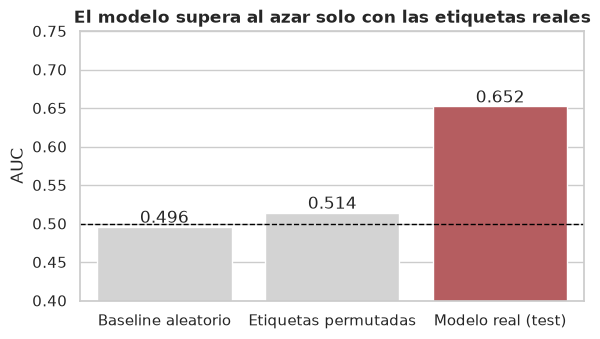

In [47]:
evidencia_auc = pd.DataFrame({'condición': ['Baseline aleatorio', 'Etiquetas permutadas', 'Modelo real (test)'],
                              'AUC': [auc_b1, auc_b3, auc_test]})
fijar_tamano(6.5, 3.5)
ax = sns.barplot(data=evidencia_auc, x='condición', y='AUC', hue='condición', legend=False,
                 palette=['lightgray', 'lightgray', COLOR_POS])
ax.axhline(0.5, ls='--', color='black', lw=1)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f')
ax.set_ylim(0.4, 0.75); ax.set_xlabel('')
ax.set_title('El modelo supera al azar solo con las etiquetas reales');

> **Lectura:** el AUC es ≈ 0.65 (0.65-0.67 entre folds), claramente por encima del azar y estable, pero **modesto**.
> Es lo esperado: reingresos hospitalarios son difíciles de predecir con variables administrativas/clínicas básicas
> (la literatura reporta AUC de 0.60-0.70 con este dataset). El objetivo del TP no es maximizar la métrica sino
> verificar que **los datos preparados contienen señal y no tienen fugas**, y ambas cosas se cumplen.

## 15. *(Opcional)* Entrenamiento y comparación de modelos

Se activa con `ENTRENAR_MODELO = True` (sección 0). Compara **estrategias de balanceo** y un modelo no lineal.

**Buenas prácticas aplicadas**
* **Umbral de decisión elegido con predicciones fuera de muestra** (out-of-fold) del train, nunca con el test.
  Con clases desbalanceadas el umbral 0.5 casi nunca es el óptimo.
* **Validación cruzada agrupada por paciente** (no hay fuga entre folds).
* Se reportan **ROC-AUC** (ranking global) y **PR-AUC** (más sensible con clase minoritaria; el azar equivale a la prevalencia ≈ 0.12).
* El test se usa **una sola vez**, al final.

*Nota:* los parámetros del pipeline se estimaron con todo train, por lo que los folds internos son levemente
optimistas; el test, en cambio, está completamente aislado.

In [48]:
def proba_out_of_fold(fabrica, X, y, grupos, submuestrear=False) -> np.ndarray:
    """Probabilidades fuera de muestra con CV agrupada. Con `submuestrear` el balanceo se hace dentro de cada fold."""
    oof = np.zeros(len(y))
    for fit_idx, val_idx in cv_interna.split(X, y, groups=grupos):
        X_fit, y_fit = X.iloc[fit_idx], y.iloc[fit_idx]
        if submuestrear:
            X_fit, y_fit = submuestreo_aleatorio(X_fit, y_fit)
        oof[val_idx] = fabrica().fit(X_fit, y_fit).predict_proba(X.iloc[val_idx])[:, 1]
    return oof


def umbral_maximo_f1(y, proba) -> float:
    precision, recall, umbrales = precision_recall_curve(y, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(umbrales[np.argmax(f1)])


def evaluar(nombre, proba, y, umbral) -> dict:
    pred = proba >= umbral
    return {'modelo': nombre, 'ROC-AUC': roc_auc_score(y, proba), 'PR-AUC': average_precision_score(y, proba),
            'recall': recall_score(y, pred), 'precisión': precision_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred), 'umbral': umbral}


if ENTRENAR_MODELO:
    n_pca = UMBRALES_PCA[90]
    candidatos = {
        'LogReg · sin balanceo': (lambda: LogisticRegression(max_iter=1000), False, Xtr, Xte),
        'LogReg · class_weight': (lambda: LogisticRegression(max_iter=1000, class_weight='balanced'), False, Xtr, Xte),
        'LogReg · submuestreo': (lambda: LogisticRegression(max_iter=1000), True, Xtr, Xte),
        'LogReg · PCA 90 %': (lambda: LogisticRegression(max_iter=1000, class_weight='balanced'), False,
                              pd.DataFrame(pca.transform(Ztr)[:, :n_pca]), pd.DataFrame(pca.transform(Zte)[:, :n_pca])),
        'HistGB · class_weight': (lambda: HistGradientBoostingClassifier(
            class_weight='balanced', max_iter=200, learning_rate=0.08, random_state=RANDOM_STATE), False, Xtr, Xte),
    }
    resultados, probas_test = [], {}
    for nombre, (fabrica, submuestrear, X_a, X_b) in candidatos.items():
        oof = proba_out_of_fold(fabrica, X_a, y_train, grupos_train, submuestrear)
        umbral = umbral_maximo_f1(y_train, oof)                       # umbral elegido SIN mirar el test
        X_fit, y_fit = submuestreo_aleatorio(X_a, y_train) if submuestrear else (X_a, y_train)
        proba_te = fabrica().fit(X_fit, y_fit).predict_proba(X_b)[:, 1]
        probas_test[nombre] = proba_te
        resultados.append(evaluar(nombre, proba_te, y_test, umbral))
    tabla_modelos = pd.DataFrame(resultados).set_index('modelo').round(3)
    print(f'Referencia: PR-AUC de un clasificador aleatorio = prevalencia = {y_test.mean():.3f}')
    display(tabla_modelos)
else:
    print('Entrenamiento omitido (ENTRENAR_MODELO = False)')

Referencia: PR-AUC de un clasificador aleatorio = prevalencia = 0.113


,ROC-AUC,PR-AUC,recall,precisión,F1,umbral
modelo,,,,,,
LogReg · sin balanceo,0.652,0.197,0.436,0.195,0.270,0.135
LogReg · class_weight,0.652,0.195,0.458,0.191,0.270,0.542
LogReg · submuestreo,0.650,0.193,0.495,0.184,0.269,0.529
LogReg · PCA 90 %,0.643,0.189,0.437,0.184,0.259,0.544
HistGB · class_weight,0.661,0.212,0.417,0.205,0.275,0.554


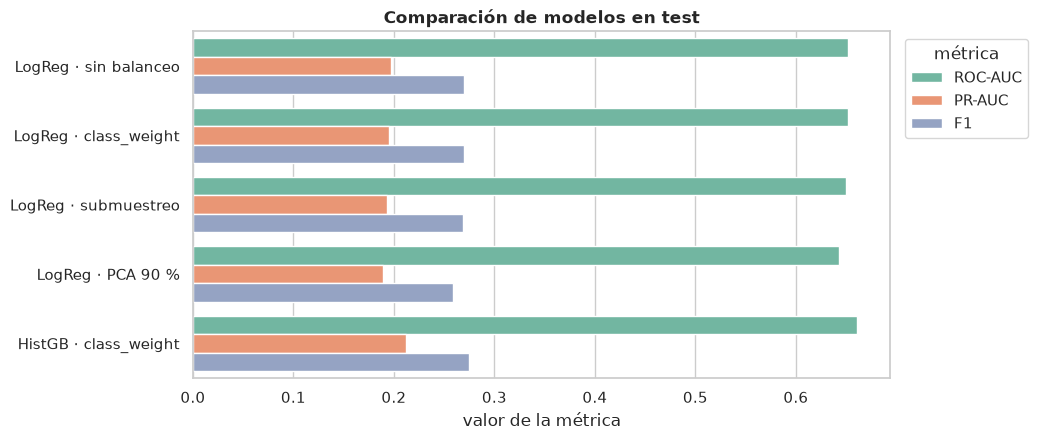

In [49]:
if ENTRENAR_MODELO:
    largo_met = tabla_modelos[['ROC-AUC', 'PR-AUC', 'F1']].reset_index().melt(id_vars='modelo', var_name='métrica',
                                                                                 value_name='valor')
    fijar_tamano(9, 4.5)
    ax = sns.barplot(data=largo_met, x='valor', y='modelo', hue='métrica', orient='h', palette='Set2')
    sns.move_legend(ax, 'upper left', bbox_to_anchor=(1.01, 1))     # fuera del área de barras
    ax.set_title('Comparación de modelos en test'); ax.set_ylabel(''); ax.set_xlabel('valor de la métrica')

> **Cómo leer la comparación**
> * **Balancear no cambia el ranking, cambia el punto de operación:** el ROC-AUC y PR-AUC de la regresión logística
>   son prácticamente iguales con `class_weight`, submuestreo o sin balanceo (≈ 0.65). Lo que cambia es el umbral óptimo
>   (con `class_weight` o submuestreo la probabilidad queda "recentrada" cerca de 0.5; sin balanceo el umbral óptimo
>   es ≈ 0.13). Es el resultado esperado: reponderar la pérdida mueve la frontera, no crea información.
> * El submuestreo **no mejora** y descarta ≈ 87 % de los negativos → `class_weight` es la opción preferible.
> * **PCA 90 %** rinde levemente peor que usar las features originales (pierde algo de señal en las componentes descartadas
>   y desde el punto de vista práctico no simplifica: ≈ 88 componentes frente a 118 features).
> * El modelo no lineal (**HistGB**) mejora poco (ROC-AUC ≈ 0.66): la señal disponible en estas variables es limitada,
>   no el algoritmo. Las métricas (F1 ≈ 0.27, PR-AUC ≈ 0.2 frente a 0.11 del azar) son coherentes con la literatura sobre este dataset.

Mejor modelo por ROC-AUC: HistGB · class_weight


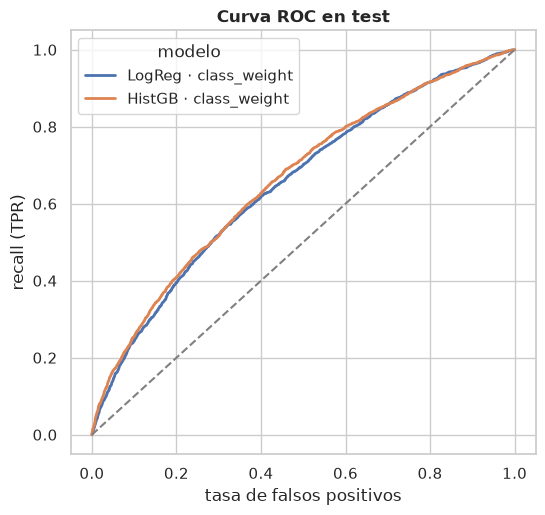

In [50]:
if ENTRENAR_MODELO:
    mejor = tabla_modelos['ROC-AUC'].idxmax()
    curvas = []
    for nombre in ['LogReg · class_weight', 'HistGB · class_weight']:
        fpr, tpr, _ = roc_curve(y_test, probas_test[nombre])
        curvas.append(pd.DataFrame({'FPR': fpr, 'TPR': tpr, 'modelo': nombre}))
    fijar_tamano(6, 5.5)
    ax = sns.lineplot(data=pd.concat(curvas), x='FPR', y='TPR', hue='modelo', lw=2)
    ax.plot([0, 1], [0, 1], ls='--', color='gray')
    ax.set_title('Curva ROC en test'); ax.set_xlabel('tasa de falsos positivos'); ax.set_ylabel('recall (TPR)')
    print(f'Mejor modelo por ROC-AUC: {mejor}')

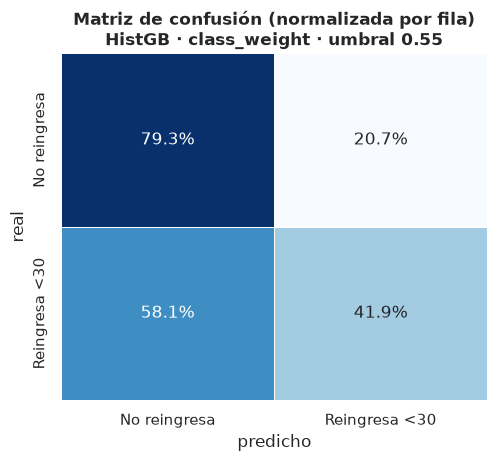

In [51]:
if ENTRENAR_MODELO:
    umbral_mejor = tabla_modelos.loc[mejor, 'umbral']
    cm = confusion_matrix(y_test, probas_test[mejor] >= umbral_mejor)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    etiquetas = ['No reingresa', 'Reingresa <30']
    fijar_tamano(5.5, 4.5)
    ax = sns.heatmap(pd.DataFrame(cm_pct, index=etiquetas, columns=etiquetas), annot=True, fmt='.1%', cmap='Blues',
                     cbar=False, linewidths=.5)
    ax.set_title(f'Matriz de confusión (normalizada por fila)\n{mejor} · umbral {umbral_mejor:.2f}')
    ax.set_xlabel('predicho'); ax.set_ylabel('real')

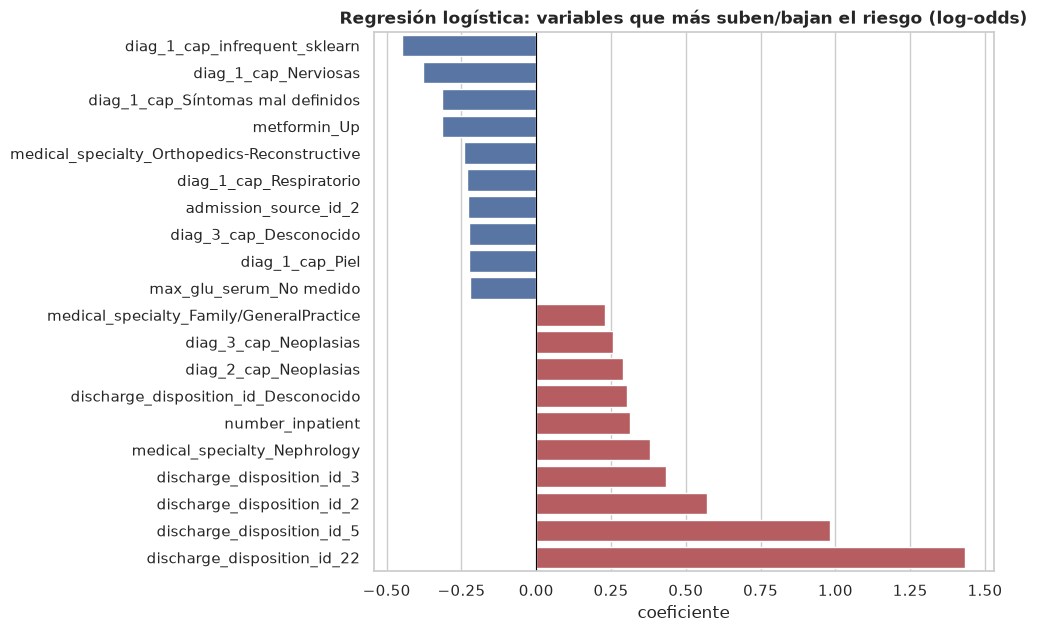

In [52]:
if ENTRENAR_MODELO:
    # Interpretabilidad: coeficientes de la regresión logística (válidos porque las variables están estandarizadas)
    lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(Xtr, y_train)
    coef = pd.Series(lr.coef_[0], index=Xtr.columns)
    extremos = pd.concat([coef.nlargest(10), coef.nsmallest(10)]).sort_values().reset_index()
    extremos.columns = ['feature', 'coeficiente']
    fijar_tamano(8, 7)
    ax = sns.barplot(data=extremos, x='coeficiente', y='feature', hue=extremos['coeficiente'] > 0,
                     palette={True: COLOR_POS, False: COLOR_NEG}, legend=False, orient='h')
    ax.axvline(0, color='black', lw=.8)
    ax.set_title('Regresión logística: variables que más suben/bajan el riesgo (log-odds)'); ax.set_ylabel('')

## 16. Conclusiones

### Hallazgos del dataset
* **101 766 internaciones, 71 518 pacientes.** Clase positiva (`<30`) ≈ 11 %: problema **desbalanceado**.
* Faltantes de **cuatro tipos distintos**: `weight` (MNAR/por diseño), laboratorios (estructural), `medical_specialty`
  (MAR) y `race` (MAR leve). Además, **entre 4.6 % y 10.2 % de nulos encubiertos** en los códigos de admisión/alta, detectados con
  el diccionario oficial.
* La etiqueta tiene **censura a la derecha**: la clase 0 mezcla "no volvió" con "no se observó".
* Las variables numéricas son conteos cero-inflados con colas largas (reales, no errores).
* Los mejores predictores son el **historial de internaciones/urgencias**, el **destino al alta** y la **carga clínica** (diagnósticos, estadía, medicación).

### Decisiones de preparación y su justificación
| Aspecto | Decisión | Porqué |
|---|---|---|
| Split | `StratifiedGroupKFold` por paciente | Evita fuga por identidad sin perder filas ni positivos |
| Faltantes | Categoría propia, no imputación | Ausencia estructural/MNAR es informativa; imputar inventaría datos |
| Outliers | Winsorización p1-p99 + `log1p` | Son valores reales; se limita su influencia sin eliminarlos |
| Codificación | Ordinal (edad, niveles) + one-hot con frecuencia mínima | Respeta el orden; controla la dimensión |
| Discretización | Visitas ambulatorias/emergencia en 4 niveles | Cero-inflación y colas extremas |
| Balanceo | `class_weight` (principal) + submuestreo evaluado | No altera datos; SMOTE inválido sobre dummies |
| Selección | Varianza + correlación + información mutua | Elimina quasi-constantes; el filtro de correlación no encontró pares > 0.90 (no hay redundancia severa) |
| PCA | Evaluado, **no adoptado** | Poca compresión con one-hot y pérdida de interpretabilidad |

### Verificación
La matriz final pasó **11 pruebas estructurales** y **5 pruebas empíricas** (baseline, modelo real, permutación de
etiquetas, brecha train-test y estabilidad). El dataset es apto para entrenar; la señal es **real pero modesta**.

### Limitaciones y próximos pasos
1. Censura a la derecha en la etiqueta (no corregible sin datos longitudinales completos).
2. Datos 1999-2008: posible *drift* respecto de la práctica clínica actual.
3. Variables sensibles (`race`, `gender`, `age`): conviene una **auditoría de equidad** (métricas por subgrupo) antes de cualquier uso real.
4. Próximos pasos: tuning con CV agrupada, calibración de probabilidades y análisis de costo-beneficio del umbral.

In [53]:
if GUARDAR_SALIDA:
    salida = Path('salida'); salida.mkdir(exist_ok=True)
    Xtr.assign(target=y_train.to_numpy()).to_csv(salida / 'train_procesado.csv.gz', index=False)
    Xte.assign(target=y_test.to_numpy()).to_csv(salida / 'test_procesado.csv.gz', index=False)
    print(f'Matrices guardadas en {salida.resolve()}')